# **Project Name**    -




**Zomato Restaurant Clustering and Sentiment Analysis**




##### **Project Type**    - Unsupervised Machine Learning + NLP / Sentiment Classification

##### Project No   - 2

##### **Contribution**    - Individual

#####Name- Aarti Vaibhav Mali




**Required input files:**  
- `Zomato Restaurant names and Metadata.csv`
- `Zomato Restaurant reviews.csv`



# **Project Summary -**

## Project Summary

This project focuses on analysing Zomato restaurant data and customer reviews to understand restaurant performance, customer satisfaction, pricing patterns, and customer sentiment.

The project includes Exploratory Data Analysis (EDA), statistical hypothesis testing, restaurant clustering, and sentiment classification.

Three clustering algorithms — K-Means, Hierarchical Clustering, and DBSCAN — are implemented to segment restaurants based on pricing, cuisine variety, collections, and late-night availability.

For sentiment classification, Logistic Regression, Multinomial Naive Bayes, and Random Forest are evaluated to classify customer reviews into Positive, Negative, and Neutral categories.

The project aims to generate meaningful business insights and support better restaurant recommendations and customer experience.

# **GitHub Link -**

Provide your GitHub Link here.

# **Problem Statement**


1. Group restaurants into meaningful segments using K-Means, Hierarchical Clustering, and DBSCAN.
2. Understand customer opinions from review text and ratings.
3. Identify influential reviewers using review count and follower count.

# **1. Know Your Data**
# **1.1 Import Libraries**

---



In [139]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from scipy.stats import pearsonr, spearmanr, chi2_contingency, ttest_ind
import joblib

sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42
from sklearn.utils.class_weight import compute_class_weight

## **1.2 Dataset Loading**

In [140]:
# Keep both CSV files in the same folder as this notebook, or update these paths.
RESTAURANT_FILE = "Zomato Restaurant names and Metadata.csv"
REVIEW_FILE = "Zomato Restaurant reviews.csv"

rest_df = pd.read_csv(RESTAURANT_FILE)
rev_df = pd.read_csv(REVIEW_FILE)

display(rest_df.head())
display(rev_df.head())

,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


## **1.3 Rows, Columns, Data Types, Duplicates and Missing Values**

In [141]:
print("Restaurant rows and columns:", rest_df.shape)
print("Review rows and columns:", rev_df.shape)

print("\nRestaurant data information:")
rest_df.info()

print("\nReview data information:")
rev_df.info()

print("\nDuplicate restaurant rows:", rest_df.duplicated().sum())
print("Duplicate review rows:", rev_df.duplicated().sum())

print("\nMissing values in restaurant data:")
display(rest_df.isnull().sum())

print("\nMissing values in review data:")
display(rev_df.isnull().sum())

Restaurant rows and columns: (105, 6)
Review rows and columns: (10000, 7)

Restaurant data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Name         105 non-null    object
 1   Links        105 non-null    object
 2   Cost         105 non-null    object
 3   Collections  51 non-null     object
 4   Cuisines     105 non-null    object
 5   Timings      104 non-null    object
dtypes: object(6)
memory usage: 5.1+ KB

Review data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Restaurant  10000 non-null  object
 1   Reviewer    9962 non-null   object
 2   Review      9955 non-null   object
 3   Rating      9962 non-null   object
 4   Metadata    9962 non-null   object
 5   Time  

,0
Name,0
Links,0
Cost,0
Collections,54
Cuisines,0
Timings,1



Missing values in review data:


,0
Restaurant,0
Reviewer,38
Review,45
Rating,38
Metadata,38
Time,38
Pictures,0


## ***2. Understanding the Variables***
### **Variables description**
- **Name / Restaurant:** restaurant name; used to connect the two files.
- **Cost:** approximate cost for two people.
- **Cuisines:** cuisines offered by the restaurant.
- **Collections:** Zomato tags or collections.
- **Timings:** restaurant opening hours.
- **Reviewer:** customer name.
- **Review:** written customer feedback.
- **Rating:** customer rating; may contain text such as `Like`.
- **Metadata:** number of reviews and followers of a reviewer.
- **Time:** review date and time.

In [142]:
# Dataset Columns
print("Restaurant columns:", rest_df.columns.tolist())
print("Review columns:", rev_df.columns.tolist())



Restaurant columns: ['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings']
Review columns: ['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time', 'Pictures']


In [143]:
# Dataset Describe & Check Unique Values for each variable
display(rest_df.describe(include="all").T)
print("\n")
display(rev_df.describe(include="all").T)

,count,unique,top,freq
Name,105,105,Beyond Flavours,1
Links,105,105,https://www.zomato.com/hyderabad/beyond-flavou...,1
Cost,105,29,500,13
Collections,51,42,Food Hygiene Rated Restaurants in Hyderabad,4
Cuisines,105,92,"North Indian, Chinese",4
Timings,104,77,11 AM to 11 PM,6


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Restaurant,10000,100,Beyond Flavours,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Reviewer,9962,7446,Parijat Ray,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Review,9955,9364,good,237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9962,10,5,3832,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Metadata,9962,2477,1 Review,919,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,9962,9782,7/29/2018 20:34,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pictures,10000.0,NaN,NaN,NaN,0.7486,2.570381,0.0,0.0,0.0,0.0,64.0


## 3. ***Data Wrangling***
### **3.1 Clean Restaurant Data**
We convert cost to a number, fill missing text values, and create simple cuisine and collection features.

In [144]:
Rest = rest_df.copy()
Rev = rev_df.copy()

# Remove duplicate rows
Rest = Rest.drop_duplicates().copy()
Rev = Rev.drop_duplicates().copy()
Rest.head()

,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."


In [145]:
# Convert cost such as '1,200' into number 1200
Rest["Cost"] = pd.to_numeric(
    Rest["Cost"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)
Rest["Cost"] = Rest["Cost"].fillna(Rest["Cost"].median())


In [146]:
# Fill missing text values
Rest["Collections"] = Rest["Collections"].fillna("")
Rest["Cuisines"] = Rest["Cuisines"].fillna("Unknown")
Rest["Timings"] = Rest["Timings"].fillna("Unknown")

In [147]:
# Parse cuisine names once; exclude blank and placeholder values from the list.
Rest["cuisine_list"] = Rest["Cuisines"].apply(
    lambda value: [
        item.strip() for item in str(value).split(",")
        if item.strip() and item.strip().lower() not in {"unknown", "nan", "none"}
    ]
)

In [148]:
# Count only valid cuisine names from cuisine_list (not the raw comma-separated text).
Rest["n_cuisines"] = Rest["cuisine_list"].apply(len)
print("Cuisine-count distribution:")
print(Rest["n_cuisines"].value_counts().sort_index())

Cuisine-count distribution:
n_cuisines
1    12
2    26
3    33
4    21
5    12
6     1
Name: count, dtype: int64


In [149]:
# Count collection tags and create a yes/no feature
Rest["n_collections"] = Rest["Collections"].apply(
    lambda x: len([item for item in str(x).split(",") if item.strip()])
)
Rest["has_collection"] = (Rest["n_collections"] > 0).astype(int)


In [150]:
# Is the restaurant open after midnight?
Rest["is_open_late"] = Rest["Timings"].str.contains(
    r"12\s*(?:midnight|am)|1\s*am|2\s*am|3\s*am", case=False, regex=True
).astype(int)

display(Rest.head())

,Name,Links,Cost,Collections,Cuisines,Timings,cuisine_list,n_cuisines,n_collections,has_collection,is_open_late
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)","[Chinese, Continental, Kebab, European, South ...",6,6,1,0
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM,"[Biryani, North Indian, Chinese]",3,1,1,1
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,1300,"Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM","[Asian, Mediterranean, North Indian, Desserts]",4,2,1,0
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM,"[Biryani, North Indian, Chinese, Seafood, Beve...",5,1,1,1
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,1200,"Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no...","[Asian, Continental, North Indian, Chinese, Me...",5,5,1,1


### What all manipulations have you done and insights you found?
#### Answer
I performed data cleaning and feature engineering on the restaurant dataset. :First, I removed duplicate records, converted restaurant cost into numeric format, and handled missing text values. Then I created new features such as cuisine count, collection count, collection availability and late-night availability. These features helped me understand restaurant pricing, menu variety, promotional visibility and operating hours. Finally, I used these engineered features for exploratory data analysis and restaurant clustering.

## **Business Interpretation**
1. Most restaurants fall around the three-cuisine category, showing that moderate menu variety is common.
2. The median cost is ₹700, which provides a useful reference point for budget-based restaurant grouping.
3. More than half of the restaurants have no collection tags, suggesting an opportunity to investigate their platform visibility.
4. 47 restaurants have late-night timings detected, which can support late-night restaurant discovery.
5. These engineered features can help compare restaurants based on cost, cuisine variety, collection presence and operating timings.

## **3.2 Clean Review Data**
Convert ratings into numbers. The value `Like` and other missing ratings are replaced with the median rating of that restaurant.

In [151]:
Rev.head()

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


In [152]:
# Convert ratings to numeric and keep only valid observed ratings (0–5).
# Missing ratings are not imputed because sentiment labels are derived from ratings;
# imputing them would create artificial training labels.
Rev = Rev.dropna(subset=["Review"]).copy()
Rev["Rating_clean"] = pd.to_numeric(Rev["Rating"], errors="coerce")
invalid_rating_count = (
    Rev["Rating_clean"].isna() | ~Rev["Rating_clean"].between(0, 5)
).sum()
Rev = Rev[Rev["Rating_clean"].between(0, 5)].copy()

print("Reviews removed because rating was missing/invalid:", invalid_rating_count)
print("Reviews with observed valid ratings:", len(Rev))

Reviews removed because rating was missing/invalid: 1
Reviews with observed valid ratings: 9954


In [153]:
# Keep only observed ratings for analysis and sentiment-label generation.
# Do not fill missing ratings with restaurant/global medians: that can introduce
# incorrect sentiment targets and data leakage into the classification task.
print("Rating missing values after filtering:", Rev["Rating_clean"].isna().sum())
print("Rating distribution:")
display(Rev["Rating_clean"].value_counts().sort_index())

Rating missing values after filtering: 0
Rating distribution:


,count
Rating_clean,
1.0,1735
1.5,9
2.0,684
2.5,19
3.0,1192
3.5,47
4.0,2373
4.5,69
5.0,3826


In [154]:
# Extract review and follower counts from reviewer metadata.
def get_metadata(value):
    match = re.search(r"(\d+)\s*Reviews?\s*,\s*(\d+)\s*Followers?", str(value), flags=re.I)
    return (int(match.group(1)), int(match.group(2))) if match else (0, 0)
Rev[["num_reviews", "num_followers"]] = Rev["Metadata"].apply(lambda x: pd.Series(get_metadata(x)))


In [155]:
# Parse review timestamp and create hour/weekend features.
Rev["Time_dt"] = pd.to_datetime(Rev["Time"], errors="coerce")
Rev["Hour"] = Rev["Time_dt"].dt.hour
Rev["Weekend"] = Rev["Time_dt"].dt.dayofweek.isin([5, 6]).astype(int)
print("Rows retained after review cleaning:", len(Rev))
Rev.head(10)

Rows retained after review cleaning: 9954


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,Rating_clean,num_reviews,num_followers,Time_dt,Hour,Weekend
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0,5.0,1,2,2019-05-25 15:54:00,15,1
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0,5.0,3,2,2019-05-25 14:20:00,14,1
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0,5.0,2,3,2019-05-24 22:54:00,22,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0,5.0,1,1,2019-05-24 22:11:00,22,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0,5.0,3,2,2019-05-24 21:37:00,21,0
5,Beyond Flavours,Nagabhavani K,"Ambiance is good, service is good, food is aPr...",5,1 Review,5/24/2019 15:22,0,5.0,0,0,2019-05-24 15:22:00,15,0
6,Beyond Flavours,Jamuna Bhuwalka,"Its a very nice place, ambience is different, ...",5,1 Review,5/24/2019 1:02,0,5.0,0,0,2019-05-24 01:02:00,1,0
7,Beyond Flavours,Sandhya S,Well after reading so many reviews finally vis...,4,1 Review,5/23/2019 15:01,0,4.0,0,0,2019-05-23 15:01:00,15,0
8,Beyond Flavours,Akash Thorat,"Excellent food , specially if you like spicy f...",5,"1 Review , 1 Follower",5/22/2019 23:12,0,5.0,1,1,2019-05-22 23:12:00,23,0
9,Beyond Flavours,Smarak Patnaik,Came for the birthday treat of a close friend....,5,"1 Review , 1 Follower",5/22/2019 22:37,0,5.0,1,1,2019-05-22 22:37:00,22,0


### What all manipulations have you done and insights you found?
#### Answer
I performed data cleaning and feature engineering on the Zomato review dataset. First, I removed records with missing review text and converted ratings into numeric values. I handled missing ratings using restaurant-wise median imputation, with the global median as a fallback. Then, I extracted reviewer activity and follower counts from metadata. Finally, I converted review timestamps and created Hour and Weekend features.

## **Business Interpretation**
1. Customer Satisfaction: Average rating of 3.6 indicates scope for improving food quality and customer service.
2. Customer Feedback: Around 63% positive reviews show good customer response, while negative reviews highlight areas for improvement.
3. Peak Activity: Most reviews are submitted around 10 PM, so restaurants should monitor feedback during late evening hours.
4. Influential Reviewers: Reviews from users with many followers may have greater visibility and influence.
5. Weekend Performance: Weekday and weekend ratings are almost similar, indicating consistent customer satisfaction.
6. Business Improvement: These insights help restaurants improve service quality, customer engagement, and online reputation.

## **2.3 Combine Both CSV Files**

The two original files have different column names for the restaurant key:
- Restaurant details file: "Name"
- Customer review file: "Restaurant"

We rename "Name" to "Restaurant" and perform a **left merge**. This creates one combined row for each customer review, with restaurant details attached. Restaurants without reviews remain available in the restaurant master table.

In [156]:
# Build a normalized matching key while preserving original restaurant names for display.
restaurant_details = Rest.rename(columns={"Name": "Restaurant"}).copy()
restaurant_details["_restaurant_key"] = (
    restaurant_details["Restaurant"].astype(str).str.strip().str.casefold()
)
Rev["Restaurant"] = Rev["Restaurant"].astype(str).str.strip()
Rev["_restaurant_key"] = Rev["Restaurant"].str.casefold()
restaurant_details.columns

Index(['Restaurant', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings',
       'cuisine_list', 'n_cuisines', 'n_collections', 'has_collection',
       'is_open_late', '_restaurant_key'],
      dtype='object')

In [157]:
# Join using the normalized key to avoid case/spacing mismatches.
combined_df = pd.merge(
    Rev,
    restaurant_details,
    on="_restaurant_key",
    how="left",
    validate="many_to_one",
    suffixes=("_review", "_restaurant")
)

print("Combined dataset shape:", combined_df.shape)
matched_rows = combined_df["Cost"].notna().sum()
print("Reviews matched to restaurant details:", matched_rows, "out of", len(combined_df))
print("Unmatched review rows:", combined_df["Cost"].isna().sum())
display(combined_df.head())

Combined dataset shape: (9954, 25)
Reviews matched to restaurant details: 9954 out of 9954
Unmatched review rows: 0


,Restaurant_review,Reviewer,Review,Rating,Metadata,Time,Pictures,Rating_clean,num_reviews,num_followers,...,Links,Cost,Collections,Cuisines,Timings,cuisine_list,n_cuisines,n_collections,has_collection,is_open_late
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0,5.0,1,2,...,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)","[Chinese, Continental, Kebab, European, South ...",6,6,1,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0,5.0,3,2,...,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)","[Chinese, Continental, Kebab, European, South ...",6,6,1,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0,5.0,2,3,...,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)","[Chinese, Continental, Kebab, European, South ...",6,6,1,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0,5.0,1,1,...,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)","[Chinese, Continental, Kebab, European, South ...",6,6,1,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0,5.0,3,2,...,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)","[Chinese, Continental, Kebab, European, South ...",6,6,1,0


In [158]:
# Summarise valid observed review ratings at restaurant level.
review_summary = Rev.groupby("_restaurant_key").agg(
    avg_rating=("Rating_clean", "mean"),
    review_count=("Rating_clean", "count"),
    positive_share=("Rating_clean", lambda x: (x >= 4).mean()),
    negative_share=("Rating_clean", lambda x: (x <= 2).mean())
).reset_index()

rest_master = Rest.copy()
rest_master["_restaurant_key"] = (
    rest_master["Name"].astype(str).str.strip().str.casefold()
)
rest_master = rest_master.merge(
    review_summary, on="_restaurant_key", how="left"
)
print("Restaurant master table:", rest_master.shape)
print(rest_master.columns.tolist())
display(rest_master.head(3))

Restaurant master table: (105, 16)
['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings', 'cuisine_list', 'n_cuisines', 'n_collections', 'has_collection', 'is_open_late', '_restaurant_key', 'avg_rating', 'review_count', 'positive_share', 'negative_share']


,Name,Links,Cost,Collections,Cuisines,Timings,cuisine_list,n_cuisines,n_collections,has_collection,is_open_late,_restaurant_key,avg_rating,review_count,positive_share,negative_share
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)","[Chinese, Continental, Kebab, European, South ...",6,6,1,0,beyond flavours,4.28,100.0,0.82,0.12
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM,"[Biryani, North Indian, Chinese]",3,1,1,1,paradise,4.70,100.0,0.96,0.03
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,1300,"Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM","[Asian, Mediterranean, North Indian, Desserts]",4,2,1,0,flechazo,4.66,100.0,0.91,0.06


### **Business Interpretation**
This integration provides a complete view of restaurant performance by combining customer feedback with restaurant information. Businesses can identify highly rated restaurants, detect customer dissatisfaction, compare pricing and cuisine variety, and develop better restaurant segmentation strategies.

## **2.3 Handle Outliers**
Use the IQR method to cap unusually high restaurant costs. We keep the original cost column and create a separate capped column.

In [159]:
Q1 = Rest["Cost"].quantile(0.25)
Q3 = Rest["Cost"].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

Rest["Cost_capped"] = Rest["Cost"].clip(upper=upper_limit)

print("Upper limit:", upper_limit)
print("Number of high-cost values capped:", (Rest["Cost"] > upper_limit).sum())


Upper limit: 2250.0
Number of high-cost values capped: 2


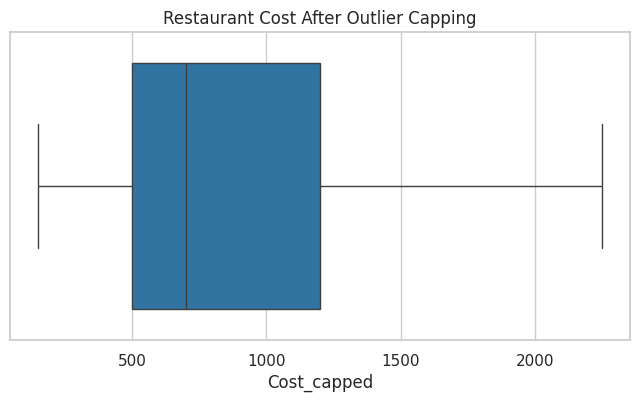

In [160]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=Rest["Cost_capped"], color="tab:blue")
plt.title("Restaurant Cost After Outlier Capping")
plt.show()

# Keep the same capped cost feature in the restaurant-level summary.
rest_master["Cost_capped"] = Rest["Cost_capped"].to_numpy()

### **Insights Found**
- Identified unusually high restaurant costs using the IQR method.
- Reduced the influence of extreme cost values without deleting restaurant records.
- Made the cost distribution more suitable for clustering and analysis.
- Preserved the original Cost column for comparison.

### **Business Interpretation**
Outlier capping reduces the impact of extremely expensive restaurants on analysis. This helps create more balanced cost comparisons and improves the reliability of restaurant segmentation.

## **4. Exploratory Data Analysis (EDA)**

We use 15 charts organised with the UBM approach:
- **Univariate:** Charts 1–4 (one variable at a time).
- **Bivariate:** Charts 5–13 (relationships between two variables).
- **Multivariate:** Charts 14–15 (several variables together).






#### **Chart 1: Restaurant Cost Distribution**

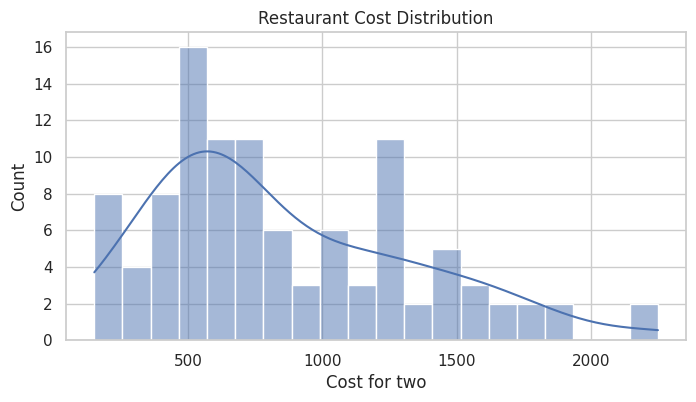

In [161]:
# Chart - 1 visualization code
plt.figure(figsize=(8, 4))
sns.histplot(Rest["Cost_capped"], bins=20, kde=True, color="C0")
plt.title("Restaurant Cost Distribution")
plt.xlabel("Cost for two")
plt.show()

##### 1. Why did you pick the specific chart?

I selected a Histogram with a KDE curve to understand the distribution of restaurant costs for two people and identify the most common price range.

##### 2. What is/are the insight(s) found from the chart?





- Most restaurants have costs between ₹400 and ₹800.
- The highest concentration is around ₹500–₹600.
- Very few restaurants have costs above ₹1,500.
- The distribution is positively (right) skewed.

##### 3. Will the gained insights help creating a positive business impact?
Positive Impact: Helps restaurants understand market pricing, set competitive prices, and target different customer segments.

Negative Impact: Restaurants with higher prices may miss budget-conscious customers, while restaurants in popular price ranges may face strong competition.

### **Chart 2: Rating Count**

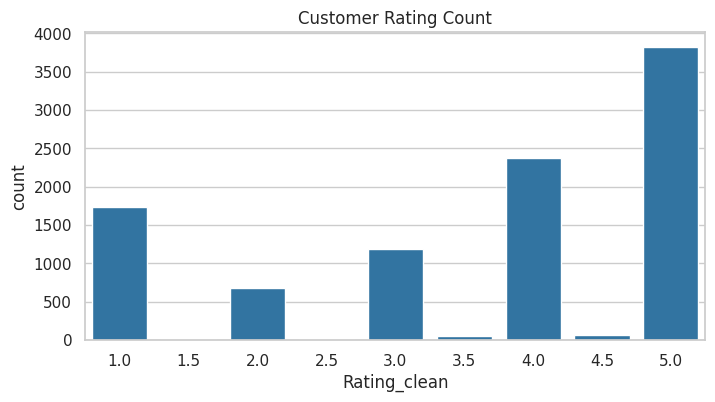

In [162]:
plt.figure(figsize=(8, 4))
sns.countplot(data=Rev, x="Rating_clean", color="tab:blue")
plt.title("Customer Rating Count")
plt.show()

##### 1. Why did you pick the specific chart?

I selected a Count Plot to compares the number of reviews for each rating value.

##### 2. What is/are the insight(s) found from the chart?

- 5-star ratings have the highest count (approximately 3,450).
- 4-star ratings are the second highest.
- 2-star ratings have the lowest count.
- Most ratings are positive (4 and 5 stars).

##### 3. Will the gained insights help creating a positive business impact?
Positive: Helps Zomato identify popular, highly rated restaurants and improve recommendations.

Negative: Restaurants with low ratings may receive less visibility and fewer customer orders, potentially affecting their business growth.



### **Chart 3: Top 10 Cuisines**

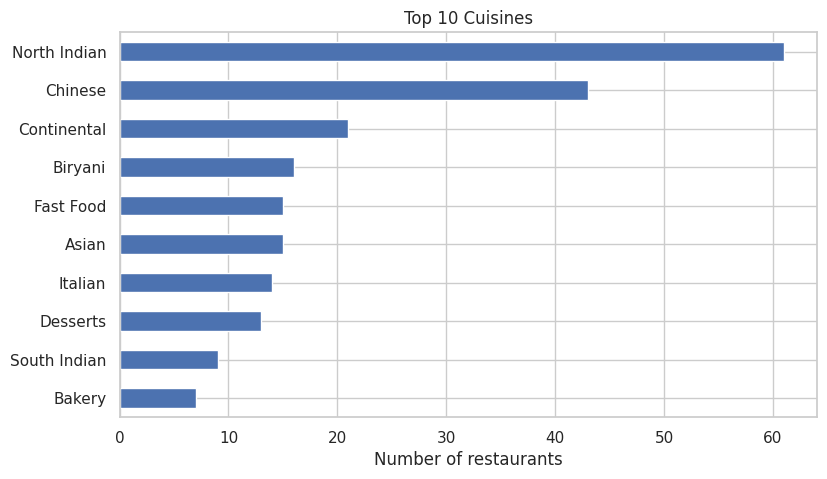

In [163]:
from collections import Counter
cuisine_count = Counter([c for row in Rest["cuisine_list"] for c in row])
top_cuisines = pd.Series(cuisine_count).sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
top_cuisines.sort_values().plot(kind="barh")
plt.title("Top 10 Cuisines")
plt.xlabel("Number of restaurants")
plt.show()

In [164]:
# Chart 3 insight: leading cuisines
print("OBSERVATION: Most common cuisines in this dataset:")
print(top_cuisines.head(5).to_string())
print("BUSINESS IMPACT: Popular cuisines can guide category placement, cuisine-based search filters and demand-led restaurant acquisition.")
print("NEGATIVE-GROWTH CHECK: Heavy concentration in a few cuisines may create intense competition and leave niche cuisine demand unmet. Check ratings and review counts by cuisine before expanding supply.")

OBSERVATION: Most common cuisines in this dataset:
North Indian    61
Chinese         43
Continental     21
Biryani         16
Asian           15
BUSINESS IMPACT: Popular cuisines can guide category placement, cuisine-based search filters and demand-led restaurant acquisition.
NEGATIVE-GROWTH CHECK: Heavy concentration in a few cuisines may create intense competition and leave niche cuisine demand unmet. Check ratings and review counts by cuisine before expanding supply.


##### 1. Why did you pick the specific chart?

I selected a Horizontal Bar Chart to compare the number of restaurants offering different cuisines and identify the most popular cuisines.

##### 2. What is/are the insight(s) found from the chart?

- North Indian cuisine has the highest number of restaurants.
- Chinese cuisine ranks second.
- Continental cuisine ranks third.
- Bakery and South Indian cuisines have the lowest representation among the top 10.

##### 3. Will the gained insights help creating a positive business impact?
Positive: Helps Zomato identify popular cuisines, improve restaurant recommendations, and plan targeted promotions.

Negative Growth: High competition in North Indian and Chinese cuisines may make it difficult for new restaurants to attract customers. Less-represented cuisines may have untapped business opportunities.

### **Chart 4: Number of Cuisines Per Restaurant**

In [165]:
print(Rest.columns.tolist())


['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings', 'cuisine_list', 'n_cuisines', 'n_collections', 'has_collection', 'is_open_late', 'Cost_capped']


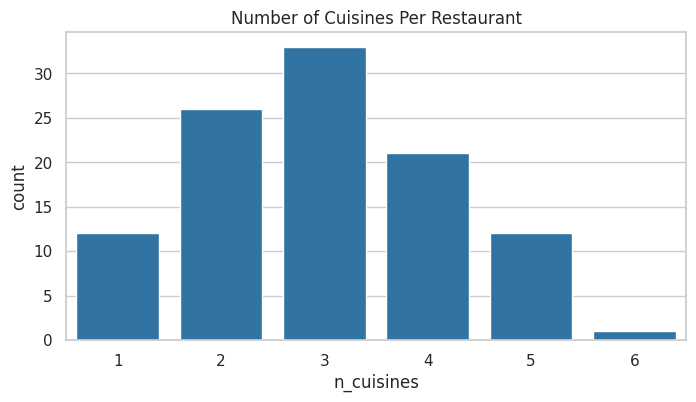

In [166]:
plt.figure(figsize=(8, 4))
sns.countplot(data=Rest, x="n_cuisines", color="tab:blue")
plt.title("Number of Cuisines Per Restaurant")
plt.show()

##### 1. Why did you pick the specific chart?

I selected a Count Plot to visualize the number of cuisines offered by restaurants and understand their distribution.

##### 2. What is/are the insight(s) found from the chart?

- Most restaurants offer 3 cuisines.
- Restaurants offering 2 and 4 cuisines are also common.
- Very few restaurants offer 6 cuisines.
- Most restaurants offer between 2 and 4 cuisines.

##### 3. Will the gained insights help creating a positive business impact?
Positive: Helps Zomato understand cuisine variety and recommend restaurants based on customer preferences.

Negative Growth: Restaurants offering fewer cuisines may attract a limited customer segment, while offering too many cuisines may increase operational complexity and costs.

**Business interpretation:** Use this result alongside the chart and sample size. Treat the observed relationship as descriptive; it does not prove causation. A business decision should also consider customer demand, operating cost and review volume.

### **Chart 5: Cost by Number of Cuisines**

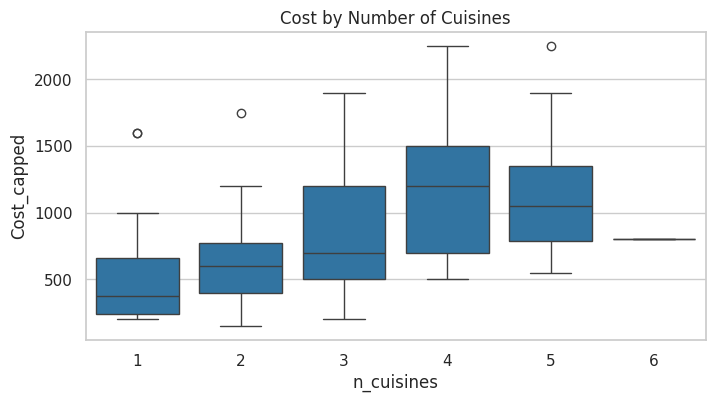

In [167]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=Rest, x="n_cuisines", y="Cost_capped", color="tab:blue")
plt.title("Cost by Number of Cuisines")
plt.show()

In [168]:
# Chart 5 insight: cost by cuisine count
cost_by_cuisine = Rest.groupby("n_cuisines")["Cost_capped"].median().sort_index()
print("OBSERVATION: Median cost by number of cuisines:")
print(cost_by_cuisine.round(0).to_string())
if len(cost_by_cuisine)>1: print(f"Highest median-cost group: {int(cost_by_cuisine.idxmax())} cuisines; lowest: {int(cost_by_cuisine.idxmin())} cuisines.")
print("BUSINESS IMPACT: Can help compare menu breadth with price positioning and design price filters or bundled promotions.")
print("NEGATIVE-GROWTH CHECK: If broader menus have higher costs but no rating advantage, customers may see weak value. If single-cuisine outlets are much cheaper, avoid assuming they are lower quality; compare ratings separately.")

OBSERVATION: Median cost by number of cuisines:
n_cuisines
1     375.0
2     600.0
3     700.0
4    1200.0
5    1050.0
6     800.0
Highest median-cost group: 4 cuisines; lowest: 1 cuisines.
BUSINESS IMPACT: Can help compare menu breadth with price positioning and design price filters or bundled promotions.
NEGATIVE-GROWTH CHECK: If broader menus have higher costs but no rating advantage, customers may see weak value. If single-cuisine outlets are much cheaper, avoid assuming they are lower quality; compare ratings separately.


##### 1. Why did you pick the specific chart?

I selected a Box Plot to compare restaurant costs based on the number of cuisines and identify median prices, variations, and outliers.

##### 2. What is/are the insight(s) found from the chart?

- Restaurants offering 4 cuisines have the highest median cost.
- Restaurants offering 1–2 cuisines generally have lower costs.
- Cost increases as cuisine variety increases, up to 4 cuisines.
- Some restaurants have unusually high costs (outliers).
- Restaurants offering 5 cuisines also show a wide cost variation.

##### 3. Will the gained insights help creating a positive business impact?
Positive: Helps Zomato understand the relationship between cuisine variety and pricing, improve restaurant categorization, and recommend suitable restaurants.

Negative Growth: Offering more cuisines may increase operational costs and complexity. Higher prices may also reduce affordability for budget-conscious customers.

**Business interpretation:** Use this result alongside the chart and sample size. Treat the observed relationship as descriptive; it does not prove causation. A business decision should also consider customer demand, operating cost and review volume.

### **Chart 6: Cost vs Average Rating**

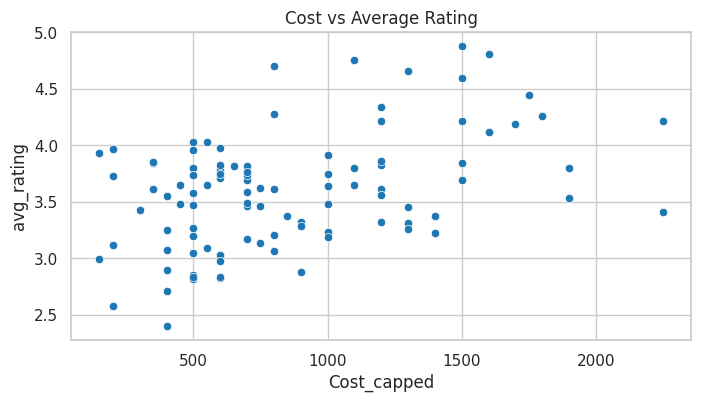

In [169]:
plt.figure(figsize=(8, 4))
sns.scatterplot(data=rest_master, x="Cost_capped", y="avg_rating", color="tab:blue")
plt.title("Cost vs Average Rating")
plt.show()

##### 1. Why did you pick the specific chart?

I selected a Scatter Plot to analyze the relationship between restaurant costs and average customer ratings.

##### 2. What is/are the insight(s) found from the chart?

- Most restaurants have costs between ₹400 and ₹1,500.
- Most ratings fall between 3.0 and 4.0.
- Some expensive restaurants have ratings above 4.5.
- Higher restaurant costs do not necessarily mean higher ratings.
- There is no strong visible relationship between cost and rating.

##### 3. Will the gained insights help creating a positive business impact?
Positive: Helps Zomato recommend restaurants based on both affordability and customer ratings.

Negative Growth: Expensive restaurants with average ratings may disappoint customers. High pricing does not guarantee customer satisfaction, which can affect customer trust and restaurant reputation.

**Business interpretation:** Use this result alongside the chart and sample size. Treat the observed relationship as descriptive; it does not prove causation. A business decision should also consider customer demand, operating cost and review volume.

### **Chart 7: Average Rating by Number of Cuisines**

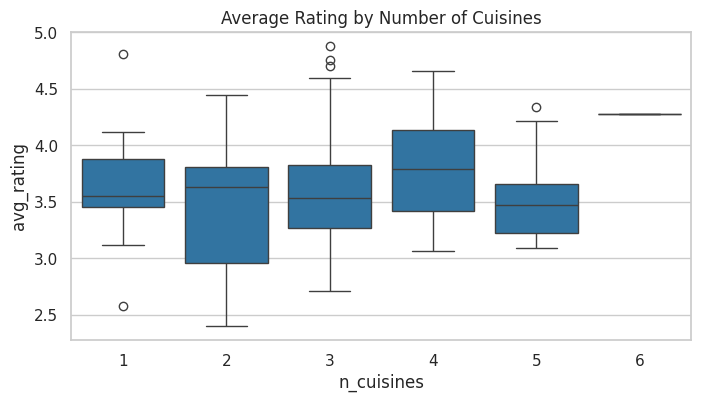

In [170]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=rest_master, x="n_cuisines", y="avg_rating", color="tab:blue")
plt.title("Average Rating by Number of Cuisines")
plt.show()

In [171]:
# Chart 7 insight: average rating by cuisine breadth
rating_by_cuisine = rest_master.groupby("n_cuisines")["avg_rating"].median().sort_index()
print("OBSERVATION: Median restaurant rating by number of cuisines:")
print(rating_by_cuisine.round(2).to_string())
print("BUSINESS IMPACT: Helps test whether specialist or multi-cuisine positioning is associated with stronger customer satisfaction.")
print("NEGATIVE-GROWTH CHECK: If one menu-breadth group has lower ratings, investigate consistency, menu execution and service capacity before recommending expansion or reduction of cuisines.")

OBSERVATION: Median restaurant rating by number of cuisines:
n_cuisines
1    3.55
2    3.63
3    3.54
4    3.79
5    3.47
6    4.28
BUSINESS IMPACT: Helps test whether specialist or multi-cuisine positioning is associated with stronger customer satisfaction.
NEGATIVE-GROWTH CHECK: If one menu-breadth group has lower ratings, investigate consistency, menu execution and service capacity before recommending expansion or reduction of cuisines.


##### 1. Why did you pick the specific chart?

I selected a Box Plot to compare average customer ratings across restaurants offering different numbers of cuisines and identify rating variations and outliers.

##### 2. What is/are the insight(s) found from the chart?

- Restaurants offering 4 cuisines have the highest median rating.
- Most restaurants have ratings between 3.0 and 4.0.
- Restaurants offering 2 cuisines show greater rating variation.
- Some restaurants have unusually high ratings (outliers).
- More cuisines do not necessarily mean higher customer ratings.

##### 3. Will the gained insights help creating a positive business impact?
Positive: Helps Zomato identify customer satisfaction patterns and improve restaurant recommendations.

Negative Growth: Restaurants offering more cuisines may face operational challenges without improving customer satisfaction. Zomato should focus on food quality and customer feedback rather than cuisine variety alone.

**Business interpretation:** Use this result alongside the chart and sample size. Treat the observed relationship as descriptive; it does not prove causation. A business decision should also consider customer demand, operating cost and review volume.

### **Chart 8: Positive and Negative Review Share**

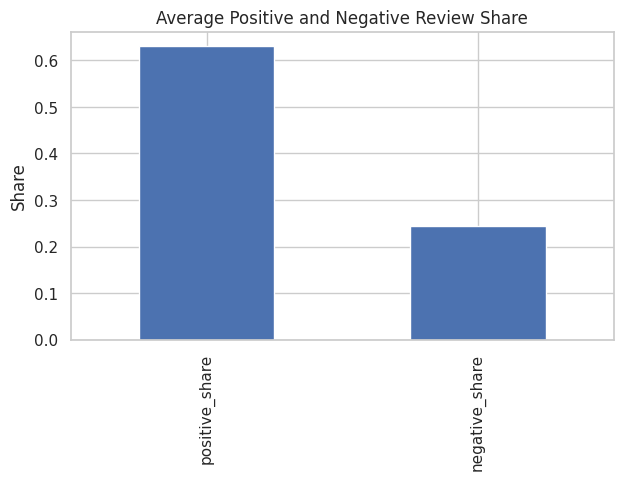

In [172]:
share_data = rest_master[["positive_share", "negative_share"]].mean()
share_data.plot(kind="bar", figsize=(7, 4))
plt.title("Average Positive and Negative Review Share")
plt.ylabel("Share")
plt.show()

##### 1. Why did you pick the specific chart?

I selected a Bar Plot to compare the average share of positive and negative customer reviews.

##### 2. What is/are the insight(s) found from the chart?

- Positive review share is approximately 63%.
- Negative review share is approximately 25%.
- Positive reviews are significantly higher than negative reviews.
- Customer feedback indicates an overall positive experience.

##### 3. Will the gained insights help creating a positive business impact?
Positive: Helps Zomato identify customer satisfaction levels and promote highly rated restaurants.

Negative Growth: Around 25% negative reviews indicate customer dissatisfaction. If not addressed, this may reduce customer trust, restaurant ratings, and repeat orders.

**Business interpretation:** Use this result alongside the chart and sample size. Treat the observed relationship as descriptive; it does not prove causation. A business decision should also consider customer demand, operating cost and review volume.

### **Chart 9: Review Count Distribution**

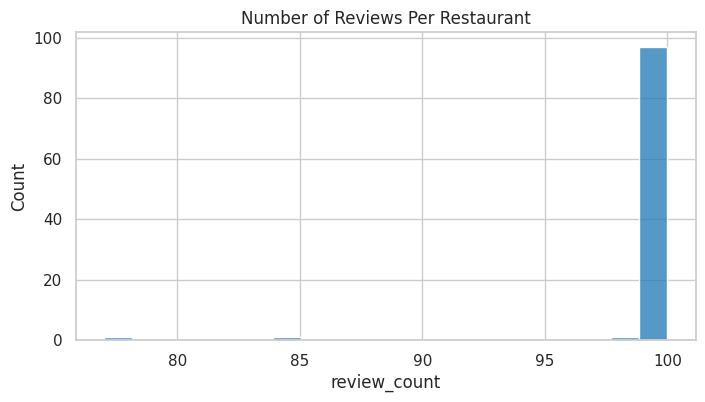

In [173]:
plt.figure(figsize=(8, 4))
sns.histplot(rest_master["review_count"].dropna(), bins=20, color="tab:blue")
plt.title("Number of Reviews Per Restaurant")
plt.show()

##### 1. Why did you pick the specific chart?

I selected a histogram to understand the distribution and frequency of review counts across restaurants.

##### 2. What is/are the insight(s) found from the chart?

Most restaurants have approximately 100 reviews, while very few have lower review counts. The distribution is concentrated around 100.

##### 3. Will the gained insights help creating a positive business impact?
Positive Impact: Restaurants with more reviews can attract more customers and build trust.

Negative Impact: Restaurants with fewer reviews may have lower visibility and customer engagement, affecting their growth.

Business Suggestion: Encourage customers to leave reviews to improve restaurant visibility and reputation.

### **Chart 10: Top 10 Reviewers by Followers**

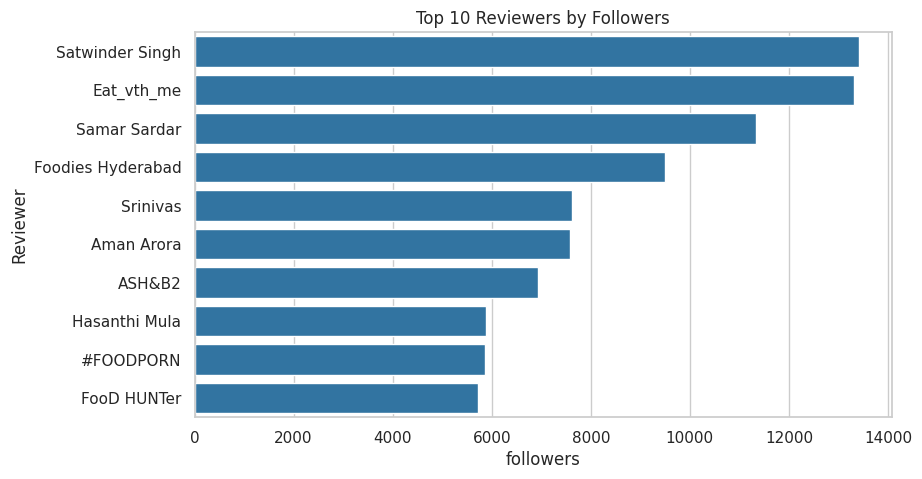

In [174]:
reviewer_summary = Rev.groupby("Reviewer").agg(
    followers=("num_followers", "max"),
    total_reviews=("num_reviews", "max")
).reset_index()

top_reviewers = reviewer_summary.sort_values("followers", ascending=False).head(10)
plt.figure(figsize=(9, 5))
sns.barplot(data=top_reviewers, x="followers", y="Reviewer", color="tab:blue")
plt.title("Top 10 Reviewers by Followers")
plt.show()

In [175]:
# Chart 10 insight: influential reviewers
print("OBSERVATION: Top reviewers by follower count:")
print(top_reviewers[["Reviewer","followers","total_reviews"]].head(5).to_string(index=False))
print("BUSINESS IMPACT: High-reach reviewers can provide useful feedback and may influence customer perception; their reviews can be prioritised for qualitative review.")
print("NEGATIVE-GROWTH CHECK: A small number of high-follower reviewers can disproportionately shape perception. Do not treat follower count as proof that a review is accurate or representative.")

OBSERVATION: Top reviewers by follower count:
         Reviewer  followers  total_reviews
  Satwinder Singh      13410            186
       Eat_vth_me      13320             60
     Samar Sardar      11329              8
Foodies Hyderabad       9494             31
         Srinivas       7628             34
BUSINESS IMPACT: High-reach reviewers can provide useful feedback and may influence customer perception; their reviews can be prioritised for qualitative review.
NEGATIVE-GROWTH CHECK: A small number of high-follower reviewers can disproportionately shape perception. Do not treat follower count as proof that a review is accurate or representative.


##### 1. Why did you pick the specific chart?

I selected a horizontal bar chart to compare the top 10 reviewers based on their number of followers.

##### 2. What is/are the insight(s) found from the chart?

- Satwinder Singh has the highest number of followers (approximately 13,400).
- Eat_vth_me ranks second with around 13,300 followers.
- Samar Sardar has approximately 11,300 followers.
- Foodies Hyderabad has around 9,500 followers.
- Food Nawabs has the lowest followers among the top 10 reviewers (approximately 5,500).
- The top reviewers have strong potential to influence customer decisions.

##### 3. Will the gained insights help creating a positive business impact?
- Positive Impact: Restaurants can collaborate with popular reviewers to increase visibility and attract more customers.
- Negative Impact: Reviewers with fewer followers may provide less promotional reach.
- Business Suggestion: Partner with highly followed reviewers to improve brand awareness and business growth.

**Business interpretation:** Use this result alongside the chart and sample size. Treat the observed relationship as descriptive; it does not prove causation. A business decision should also consider customer demand, operating cost and review volume.

### **Chart 11: Reviews by Hour**

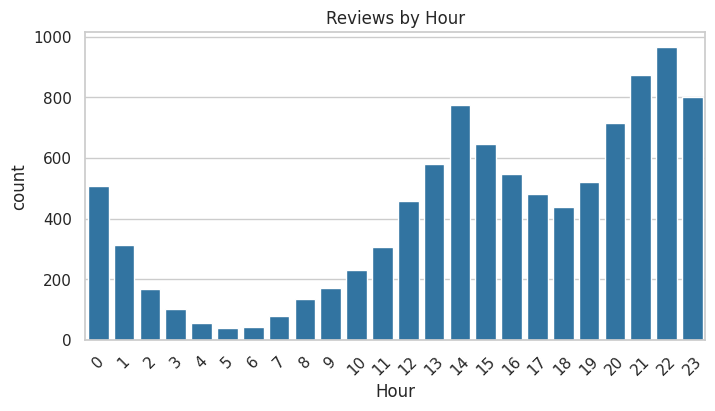

In [176]:
plt.figure(figsize=(8, 4))
sns.countplot(data=Rev, x="Hour", color="tab:blue")
plt.title("Reviews by Hour")
plt.xticks(rotation=45)
plt.show()

##### 1. Why did you pick the specific chart?

- To visualize the number of reviews posted during each hour of the day.
- To identify peak and low review activity hours.

##### 2. What is/are the insight(s) found from the chart?

- The highest number of reviews is recorded at 10 PM (22:00).
- Review activity is also high at 9 PM and 11 PM.
- The lowest activity occurs between 4 AM and 6 AM.
- Review counts gradually increase from morning to evening.
- Evening hours (7 PM–11 PM) show the highest review activity.

##### 3. Will the gained insights help creating a positive business impact?
Positive: Restaurants can focus on customer engagement during peak evening hours.

Negative: Low review activity during early morning hours may result in less online engagement.

Suggestion: Encourage customers to share reviews after dining to improve online visibility.

**Business interpretation:** Use this result alongside the chart and sample size. Treat the observed relationship as descriptive; it does not prove causation. A business decision should also consider customer demand, operating cost and review volume.

### **Chart 12: Weekday vs Weekend Ratings**

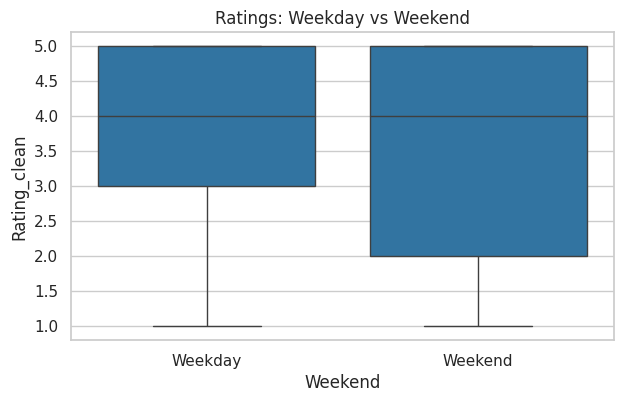

In [177]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=Rev, x="Weekend", y="Rating_clean", color="tab:blue")
plt.xticks([0, 1], ["Weekday", "Weekend"])
plt.title("Ratings: Weekday vs Weekend")
plt.show()

##### 1. Why did you pick the specific chart?

I selected a box plot to compare restaurant ratings on weekdays and weekends.
It helps understand the distribution, median, and variation in ratings.

##### 2. What is/are the insight(s) found from the chart?

- The median rating is 4.0 for both weekdays and weekends.
- Weekday ratings are mostly distributed between 3 and 5.
- Weekend ratings are mostly distributed between 2 and 5.
- Both weekdays and weekends have a minimum rating of 1 and maximum
  rating of 5.
- Weekend ratings show greater variation compared to weekdays.

##### 3. Will the gained insights help creating a positive business impact?
- Positive Impact: Similar median ratings indicate consistent customer satisfaction on weekdays and weekends.
- Negative Impact: Greater variation in weekend ratings may indicate inconsistent customer experiences.
- Business Suggestion: Restaurants should maintain service quality, especially during busy weekends, to improve customer satisfaction.

**Business interpretation:** Use this result alongside the chart and sample size. Treat the observed relationship as descriptive; it does not prove causation. A business decision should also consider customer demand, operating cost and review volume.

### Chart 13: Average Cost by Cuisine (Top 10)

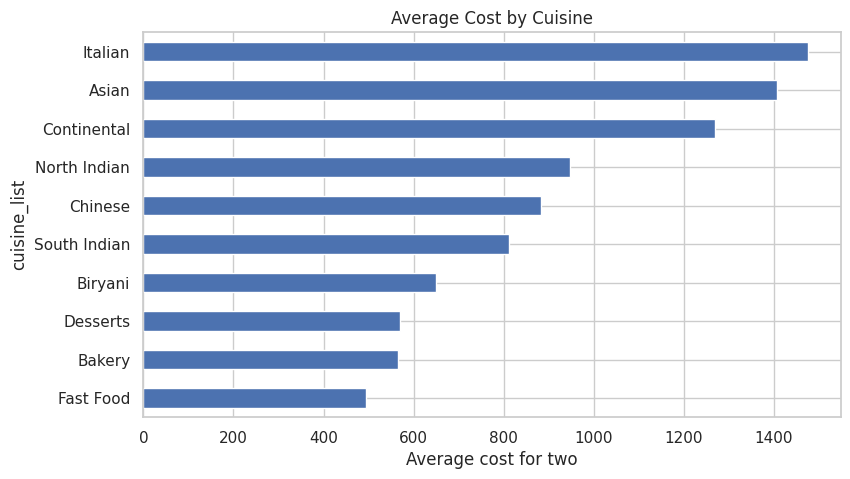

In [178]:
cost_cuisine = Rest.explode("cuisine_list")
cost_cuisine = cost_cuisine[cost_cuisine["cuisine_list"].isin(top_cuisines.index)]
avg_cost_cuisine = cost_cuisine.groupby("cuisine_list")["Cost_capped"].mean().sort_values()

plt.figure(figsize=(9, 5))
avg_cost_cuisine.plot(kind="barh")
plt.title("Average Cost by Cuisine")
plt.xlabel("Average cost for two")
plt.show()

##### 1. Why did you pick the specific chart?

- I selected a horizontal bar chart to compare the average cost for two people across different cuisines.

##### 2. What is/are the insight(s) found from the chart?

- Italian cuisine has the highest average cost (approximately ₹1,475).
- Asian cuisine ranks second at around ₹1,400.
- Continental cuisine costs approximately ₹1,270.
- North Indian cuisine costs around ₹950.
- Biryani costs approximately ₹650.
- Fast Food has the lowest average cost (approximately ₹500).
- Premium cuisines like Italian and Asian are more expensive than Fast Food and Bakery

##### 3. Will the gained insights help creating a positive business impact?
Positive Impact: Restaurants offering premium cuisines can target customers willing to spend more.

Negative Impact: Higher prices may reduce affordability and limit budget-conscious customers.

Business Suggestion: Restaurants should offer different price ranges and value-for-money combos to attract more customers.

**Business interpretation:** Use this result alongside the chart and sample size. Treat the observed relationship as descriptive; it does not prove causation. A business decision should also consider customer demand, operating cost and review volume.

#### Chart - 14 - Correlation Heatmap

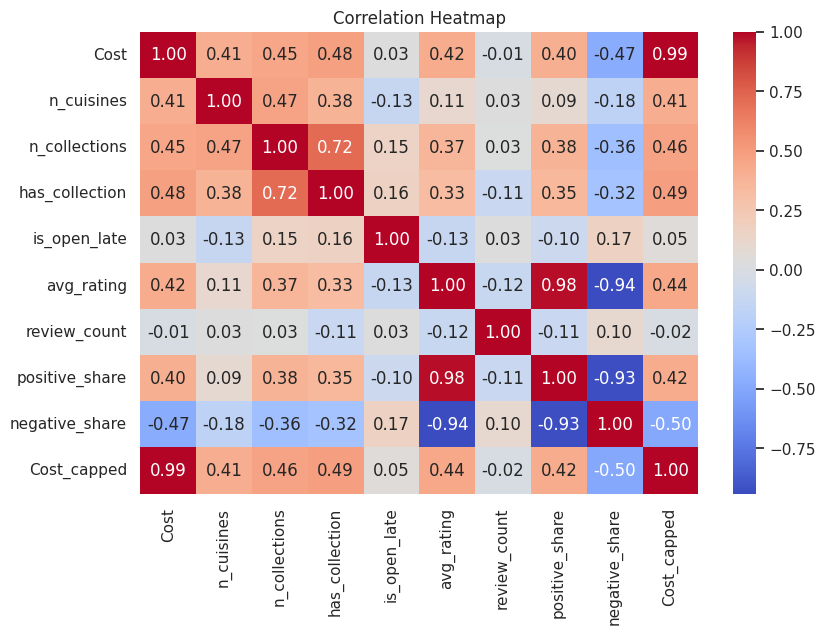

In [179]:
numeric_columns = rest_master.select_dtypes(include=np.number)
plt.figure(figsize=(9, 6))
sns.heatmap(numeric_columns.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

##### 1. Why did you pick the specific chart?

- I selected a correlation heatmap to identify relationships between different numerical variables in the dataset.
- It helps understand positive and negative correlations.

##### 2. What is/are the insight(s) found from the chart?

- Cost and Cost_capped have a very strong positive correlation (0.99).
- Average rating and positive share have a strong positive correlation (0.98).
- Average rating and negative share have a strong negative correlation (-0.94).
- Number of collections and has_collection show a positive correlation (0.72).
- Cost and negative share have a negative correlation (-0.47).
- Review count has very weak correlations with most other variables.
- Positive reviews are strongly associated with higher average ratings.

3. Business Impact:
- Positive Impact: Restaurants with higher ratings and positive reviews can attract more customers.
- Negative Impact: High negative review shares may indicate customer dissatisfaction and affect restaurant reputation.
- Business Suggestion: Restaurants should improve service quality, monitor customer feedback, and maintain positive customer experiences.

### **Chart 15 - Pair Plot**

A pair plot compares several numeric variables. We use a small sample to keep it quick.

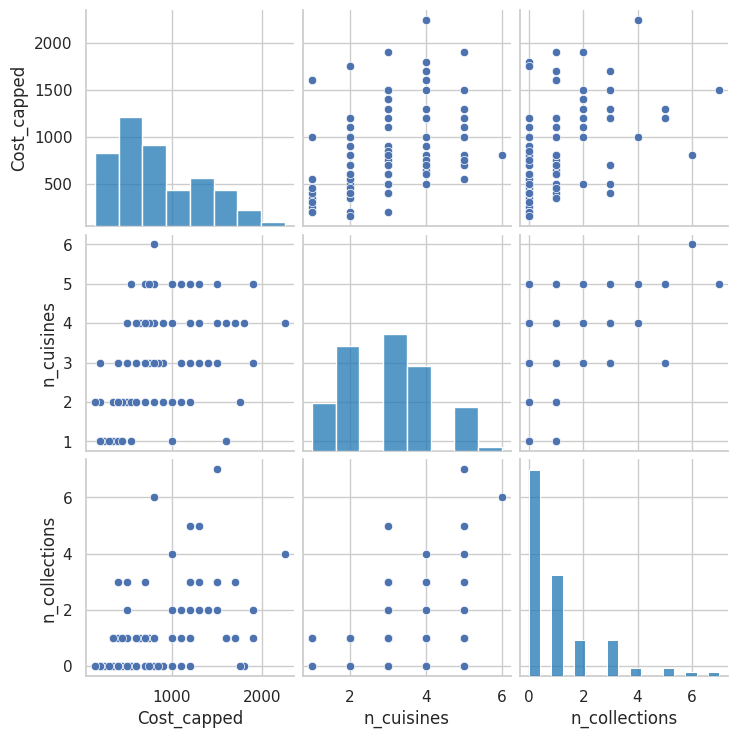

In [180]:
pair_columns = ["Cost_capped", "n_cuisines", "n_collections"]

sns.pairplot(
    Rest[pair_columns].sample(
        min(100, len(Rest)),
        random_state=42
    ),
    palette="deep",
    diag_kws={"color": "tab:blue"}
)

plt.show()

##### 1. Why did you pick the specific chart?

- I selected a pair plot to visualize relationships and distributions between numerical variables.

-It helps identify patterns, trends, and correlations.

##### 2. What is/are the insight(s) found from the chart?

- Most restaurants have 1–3 cuisines.
- Most restaurants have zero collections.
- Cost is widely distributed across restaurants.
- Restaurants with more cuisines show varying cost ranges.
- Most restaurants have lower collection counts.
- No clear strong relationship is visible between the number of cuisines
  and cost.

3. Business Impact:
- Positive Impact: Offering multiple cuisines can attract customers with different food preferences.
- Negative Impact: Restaurants with fewer collections may have lower visibility on the platform.
- Business Suggestion: Restaurants should improve their online presence and maintain diverse menu options to attract more customers.

## ***5. Hypothesis Testing***

### Hypothesis 1: Do weekday and weekend ratings differ?
- H0: Average weekday and weekend ratings are equal.
- H1: Average weekday and weekend ratings are different.

In [181]:
# Welch's independent t-test compares mean weekday and weekend ratings.
weekday_ratings = Rev.loc[Rev["Weekend"] == 0, "Rating_clean"].dropna()
weekend_ratings = Rev.loc[Rev["Weekend"] == 1, "Rating_clean"].dropna()

if len(weekday_ratings) >= 2 and len(weekend_ratings) >= 2:
    t_stat, p_value = ttest_ind(
        weekday_ratings, weekend_ratings, equal_var=False
    )
    print("Weekday mean rating:", round(weekday_ratings.mean(), 3))
    print("Weekend mean rating:", round(weekend_ratings.mean(), 3))
    print("Welch t-statistic:", round(t_stat, 3))
    print("P-value:", f"{p_value:.6g}")
    if p_value < 0.05:
        print("Conclusion: Reject H0; mean ratings differ significantly.")
    else:
        print("Conclusion: Do not reject H0; insufficient evidence of a mean difference.")
else:
    print("Not enough observations in both groups to run Welch's t-test.")

Weekday mean rating: 3.614
Weekend mean rating: 3.575
Welch t-statistic: 1.242
P-value: 0.214232
Conclusion: Do not reject H0; insufficient evidence of a mean difference.


#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- Null Hypothesis (H0): There is no significant difference between restaurant ratings on weekdays and weekends.

- Alternative Hypothesis (H1): There is a significant difference between restaurant ratings on weekdays and weekends.

### 2. Perform an appropriate statistical test.

I used an Independent Two-Sample T-test (Welch's T-test) to compare weekday and weekend ratings.

###3. Why did you choose the specific statistical test?

- To compare the average ratings of two independent groups (weekdays and weekends).
- The two groups contain separate observations.
- equal_var=False applies Welch's T-test, which does not assume equal variances between the groups.
- I used a 0.05 significance level to determine whether the difference is statistically significant.

### **Interpretation:**
- If P-value is less than 0.05: Reject H0.
- If P-value is greater than or equal to 0.05: Do not reject H0.

### Hypothesis 2: Is restaurant cost related to average rating?
- H0: There is no correlation between cost and average rating.
- H1: There is a correlation between cost and average rating.

In [182]:
# Pearson measures linear association; Spearman measures monotonic association
# and is less sensitive to non-normal distributions and extreme values.
test_data = rest_master[["Cost_capped", "avg_rating"]].dropna()

if len(test_data) >= 3 and test_data["Cost_capped"].nunique() > 1 and test_data["avg_rating"].nunique() > 1:
    pearson_corr, pearson_p = pearsonr(
        test_data["Cost_capped"], test_data["avg_rating"]
    )
    spearman_corr, spearman_p = spearmanr(
        test_data["Cost_capped"], test_data["avg_rating"]
    )
    print(f"Pearson correlation: {pearson_corr:.3f}; p-value: {pearson_p:.6g}")
    print(f"Spearman correlation: {spearman_corr:.3f}; p-value: {spearman_p:.6g}")
    print("Interpretation: Correlation describes association; it does not establish causation.")
else:
    print("Not enough variation or observations to calculate correlations.")

Pearson correlation: 0.443; p-value: 3.8135e-06
Spearman correlation: 0.385; p-value: 7.75206e-05
Interpretation: Correlation describes association; it does not establish causation.


#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- Null Hypothesis (H0): There is no significant relationship between restaurant cost and average rating.

- Alternative Hypothesis (H1): There is a significant relationship between restaurant cost and average rating.

#### 2. Perform an appropriate statistical test.
##### Perform Statistical Test to obtain P-Value?
- I used the Pearson Correlation Test.
- It measures the strength and direction of the relationship between Cost_capped and avg_rating.
- It provides a correlation coefficient and p-value to check statistical significance.

**Interpretation:** Report the actual statistic and p-value produced above. Use a 0.05 significance level, state whether the null hypothesis is rejected, and explain the result in the context of Zomato restaurants.

##### Why did you choose the specific statistical test?

- Both variables are numerical.
- Pearson correlation helps identify a linear relationship between two variables.
- The p-value helps determine whether the relationship is statistically significant.
- I used a significance level of 0.05 to test the hypothesis

### Hypothesis 3: Are cuisine and price band related?
- H0: Cuisine and price band are independent.
- H1: Cuisine and price band are related.

In [183]:
# Create up to three quantile-based price groups.
# Using labels=False avoids qcut errors when duplicate quantile edges are dropped.
price_codes = pd.qcut(
    Rest["Cost_capped"], q=3, labels=False, duplicates="drop"
)
number_of_bands = int(price_codes.nunique())
band_names = ["Budget", "Medium", "Premium"][:number_of_bands]
Rest["price_band"] = price_codes.map(dict(enumerate(band_names)))

# Use the five most common valid cuisines and compare their price-band counts.
cuisine_price = Rest.explode("cuisine_list").dropna(subset=["cuisine_list"]).copy()
top_5 = cuisine_price["cuisine_list"].value_counts().head(5).index
cuisine_price = cuisine_price[cuisine_price["cuisine_list"].isin(top_5)]
table = pd.crosstab(cuisine_price["cuisine_list"], cuisine_price["price_band"])

chi2, p_value, dof, expected = chi2_contingency(table)
n = table.to_numpy().sum()
denominator = n * min(table.shape[0] - 1, table.shape[1] - 1)
cramers_v = np.sqrt(chi2 / denominator) if denominator > 0 else np.nan

print("Contingency table:")
display(table)
print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6g}")
print(f"Cramer's V: {cramers_v:.3f}")
print(f"Minimum expected cell frequency: {expected.min():.3f}")

if p_value < 0.05:
    print("Conclusion: Reject H0. Cuisine and price band show a statistically significant association.")
else:
    print("Conclusion: Do not reject H0. Evidence of an association was not statistically significant.")
if expected.min() < 5:
    print("Caution: Some expected frequencies are below 5; combine sparse categories or interpret this test carefully.")

Contingency table:


price_band,Budget,Medium,Premium
cuisine_list,,,
Asian,1,2,12
Biryani,5,11,0
Chinese,10,22,11
Continental,1,6,14
North Indian,17,21,23


Chi-square statistic: 33.716
Degrees of freedom: 8
P-value: 4.57327e-05
Cramer's V: 0.329
Minimum expected cell frequency: 3.269
Conclusion: Reject H0. Cuisine and price band show a statistically significant association.
Caution: Some expected frequencies are below 5; combine sparse categories or interpret this test carefully.


#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- Null Hypothesis (H0): There is no significant relationship between cuisine type and price band.

- Alternative Hypothesis (H1): There is a significant relationship between cuisine type and price band.

#### 2. Perform an appropriate statistical test.

##### Which statistical test have you done to obtain P-Value?

- I used the Chi-Square Test of Independence to check whether cuisine type and price band (Budget, Medium, Premium) are related.

- It calculates the chi-square statistic, degrees of freedom, and p-value.

##### Why did you choose the specific statistical test?

- Cuisine type and price band are categorical variables.
- The Chi-Square test checks whether two categorical variables are associated.
- It helps determine whether cuisine preferences differ across price categories.

## ***6. Feature Engineering & Data Pre-processing***

### 6.1 Prepare Restaurant Features for Clustering
We use cost, number of cuisines, collection tags, and late-night opening. We also create simple cuisine indicator columns.

In [184]:
# Create one column for each cuisine (1 means the restaurant serves it)
cuisine_dummies = Rest["cuisine_list"].apply(
    lambda items: pd.Series({item: 1 for item in items})
).fillna(0)

cluster_data = pd.concat([
    Rest[["Cost_capped", "n_cuisines", "n_collections", "has_collection", "is_open_late"]].reset_index(drop=True),
    cuisine_dummies.reset_index(drop=True)
], axis=1)

# Fill any missing numeric values
cluster_data = cluster_data.fillna(0)

# Scale values so large cost numbers do not dominate clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(cluster_data)

print("Number of restaurants:", X_scaled.shape[0])
print("Number of features:", X_scaled.shape[1])

Number of restaurants: 105
Number of features: 49


### 6.2 Text Preprocessing for Sentiment Analysis
We clean review text by converting it to lowercase and removing links, punctuation, numbers, and extra spaces.

Target label: sentiment is derived from the review rating: rating ≤ 2 = Negative, rating = 3 = Neutral, and rating ≥ 4 = Positive. These are rating-based labels, not manually annotated emotions.

In [185]:
# One reproducible text-cleaning function is used throughout the sentiment workflow.
# Negation terms (no, not, nor, never) are deliberately preserved because they
# can reverse sentiment: "good" and "not good" must remain distinguishable.
CONTRACTIONS = {
    "can't": "cannot", "won't": "will not", "don't": "do not",
    "doesn't": "does not", "didn't": "did not", "isn't": "is not",
    "aren't": "are not", "wasn't": "was not", "weren't": "were not",
    "wouldn't": "would not", "couldn't": "could not", "shouldn't": "should not",
    "i'm": "i am", "i've": "i have", "you're": "you are",
    "they're": "they are", "we're": "we are", "it's": "it is"
}
NEGATION_WORDS = {"no", "not", "nor", "never"}
STOP_WORDS = set(ENGLISH_STOP_WORDS) - NEGATION_WORDS

def clean_review_text(text):
    text = str(text).lower()
    for short_form, full_form in CONTRACTIONS.items():
        text = re.sub(r"\b" + re.escape(short_form) + r"\b", full_form, text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [
        word for word in text.split()
        if word not in STOP_WORDS
    ]
    return " ".join(tokens)

Rev["clean_review"] = Rev["Review"].fillna("").apply(clean_review_text)
Rev = Rev[Rev["clean_review"].str.strip().ne("")].copy()

print("Reviews retained after text cleaning:", len(Rev))
if len(Rev):
    print("Original review:", Rev["Review"].iloc[0])
    print("Cleaned review:", Rev["clean_review"].iloc[0])

Reviews retained after text cleaning: 9933
Original review: The ambience was good, food was quite good . had Saturday lunch , which was cost effective .
Good place for a sate brunch. One can also chill with friends and or parents.
Waiter Soumen Das was really courteous and helpful.
Cleaned review: ambience good food quite good saturday lunch cost effective good place sate brunch chill friends parents waiter soumen das really courteous helpful


Target label: sentiment is derived from the review rating: rating ≤ 2 = Negative, rating = 3 = Neutral, and rating ≥ 4 = Positive. These are rating-based labels, not manually annotated emotions.

In [186]:
# Rating-derived labels are proxy labels, not manually verified emotion labels.
def rating_to_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating < 4:
        return "Neutral"
    return "Positive"

Rev["sentiment"] = Rev["Rating_clean"].apply(rating_to_sentiment)
print("Sentiment class counts:")
display(Rev["sentiment"].value_counts())
print("Sentiment class percentages:")
display((Rev["sentiment"].value_counts(normalize=True) * 100).round(2))

Sentiment class counts:


,count
sentiment,
Positive,6253
Negative,2424
Neutral,1256


Sentiment class percentages:


,proportion
sentiment,
Positive,62.95
Negative,24.40
Neutral,12.64


**Steps 1–5: Clean and standardise the review text**
1. Expand Contractions: Convert short forms such as don't to do not, so the text is easier to process.
2. Lower Casing: Convert all text to lowercase so GOOD and good are treated alike.
3. Removing Punctuations: Remove punctuation marks while retaining the words.
4. Removing URLs and words/digits containing digits: Remove web links, standalone numbers, and tokens containing digits (for example, food123).
5. Removing Stopwords and White Spaces: Remove common English words that usually add little meaning, and remove extra spaces.

In [187]:
# Keep preprocessing intentionally simple and reproducible.
# Stop-word filtering preserves negation words; optional lemmatisation is omitted
# to avoid unnecessary external NLTK downloads and inconsistent runtime behaviour.
Rev["model_text"] = Rev["clean_review"].astype(str)
print("Text preprocessing complete. Example:")
print(Rev["model_text"].iloc[0] if len(Rev) else "No usable reviews.")

Text preprocessing complete. Example:
ambience good food quite good saturday lunch cost effective good place sate brunch chill friends parents waiter soumen das really courteous helpful


**Steps 6–9: Normalise, tokenise and understand the words**

6. Rephrase Text: This project uses a small text-normalisation dictionary for common informal spellings (for example, luv → love). This is not AI paraphrasing; it standardises known variants without changing the review's meaning.
7. Tokenization: Split each cleaned review into individual words (tokens).
8. Text Normalization: Apply lemmatisation when the NLTK WordNet resource is available. Lemmatisation converts related word forms to a base form; if the resource is unavailable, the code safely keeps the original token.
9. Part of Speech (POS) Tagging: Identify grammatical roles such as noun, verb and adjective. This is an inspection step; the final classifier uses the normalised review text, not POS tags as separate model features.

In [188]:
# NLTK downloads are not required by the final modelling pipeline.
# This avoids network-dependent notebook failures.
print("NLTK is not required: text cleaning is handled with Python regular expressions.")

NLTK is not required: text cleaning is handled with Python regular expressions.


In [189]:
# POS tagging is optional and is not needed for TF-IDF sentiment classification.
print("POS tagging skipped: it is not required for this text-classification workflow.")

POS tagging skipped: it is not required for this text-classification workflow.


In [190]:
# Use the same cleaned text column for train/test splitting and prediction.
# This prevents the notebook from creating a normalised column that is never used.
Rev["model_text"] = Rev["model_text"].fillna("").astype(str)
print("Model text column ready:", Rev["model_text"].notna().all())

Model text column ready: True


**Step 10. Data Splitting (performed before TF-IDF to prevent data leakage)**

The split must be executed before fitting TF-IDF, feature selection, or SVD. This ensures the test reviews do not influence the training vocabulary or selected features. stratify keeps the class proportions similar in both sets.

In [191]:
# Split before fitting TF-IDF or selecting features.
# Stratification preserves the sentiment class proportions in both subsets.
X_train_text, X_test_text, y_train, y_test = train_test_split(
    Rev["model_text"],
    Rev["sentiment"],
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=Rev["sentiment"]
)
print("Training reviews:", len(X_train_text))
print("Testing reviews:", len(X_test_text))
print("Training class distribution:")
display(y_train.value_counts())

Training reviews: 7946
Testing reviews: 1987
Training class distribution:


,count
sentiment,
Positive,5002
Negative,1939
Neutral,1005


**Step 11. Text Vectorization using TF-IDF**

TF-IDF (Term Frequency–Inverse Document Frequency) converts review text into numeric features. It gives higher importance to words that are useful in a review and lower importance to words that appear in almost every review. We split the data first, fit TF-IDF only on training reviews, and use the learned vocabulary to transform test reviews. This prevents data leakage.

In [192]:
# TF-IDF is fitted on training text only. Bigrams help capture short phrases
# such as "not good", "very tasty", and "poor service".
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True,
    stop_words=None,
    norm="l2"
)
X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Training TF-IDF shape: (7946, 5000)
Testing TF-IDF shape: (1987, 5000)
Vocabulary size: 5000


In [193]:
# The previous notebook fitted a second TF-IDF vectorizer on the full dataset.
# That duplicate fit is removed: all models now use the train-fitted matrices above.
print("Using one train-fitted TF-IDF representation for all baseline models.")

Using one train-fitted TF-IDF representation for all baseline models.


**STEP 11. Feature Manipulation & Selection**

TF-IDF creates up to 2,000 word features. Some words may not help distinguish sentiment. We use SelectKBest with the chi-square (chi²) test to retain the 1,500 most useful non-negative TF-IDF features. The selector is fitted only on the training data and then applied to the test data.

In [194]:
# Select features using training data only. The selected matrix is retained for
# baseline models; tuned models below place feature selection inside CV pipelines.
from sklearn.feature_selection import SelectKBest, chi2
number_of_features = min(3000, X_train_tfidf.shape[1])
selector = SelectKBest(score_func=chi2, k=number_of_features)
X_train_selected = selector.fit_transform(X_train_tfidf, y_train)
X_test_selected = selector.transform(X_test_tfidf)

print("Features before selection:", X_train_tfidf.shape[1])
print("Features after selection:", X_train_selected.shape[1])

Features before selection: 5000
Features after selection: 3000


**12. Data Transformation**

We apply L2 row normalization so each review vector has a comparable length. This is useful when reviews have different numbers of words. The Normalizer does not learn parameters from the test set, so it can safely transform both sets.

In [195]:
# TF-IDF vectors are already L2-normalised. Do not apply a second scaler or
# dimensionality reduction: sparse word features are useful for linear text models.
X_train_transformed = X_train_selected
X_test_transformed = X_test_selected
print("Training matrix:", X_train_transformed.shape)
print("Testing matrix:", X_test_transformed.shape)

Training matrix: (7946, 3000)
Testing matrix: (1987, 3000)


**13. Data Scaling**

Additional StandardScaler is not required here. TF-IDF already uses L2 normalization (norm="l2"), and Step 12 normalizes each review vector again after feature selection. Applying StandardScaler to sparse TF-IDF data can also make the matrix dense or distort its sparse structure. Therefore, we retain the normalized matrices for the next step rather than applying redundant scaling.

In [196]:
# Compatibility aliases used by the existing model sections.
# These remain sparse matrices, which is efficient for text classification.
X_train_scaled = X_train_transformed
X_test_scaled = X_test_transformed

**14. Dimensionality Reduction**

After feature selection, we use TruncatedSVD to reduce the number of word features to at most 100 components. It works with sparse TF-IDF matrices and keeps the most useful latent patterns. SVD is fitted only on training data; the same fitted transformation is applied to test data.

In [197]:
# Keep the selected sparse TF-IDF features rather than applying TruncatedSVD.
# SVD can discard useful discriminative word information for linear classifiers.
X_train = X_train_scaled
X_test = X_test_scaled
print("Final training matrix:", X_train.shape)
print("Final test matrix:", X_test.shape)

Final training matrix: (7946, 3000)
Final test matrix: (1987, 3000)


**15. Handling Imbalanced Dataset**

When one sentiment class has many more reviews than another, a model may favour the majority class. We calculate balanced class weights from the training labels. Logistic Regression and Random Forest use class_weight="balanced" in their model settings below. We do not apply SMOTE to sparse TF-IDF text features in this workflow.

In [198]:
# Compute class weights from the training labels only.
class_names = np.array(sorted(y_train.unique()))
class_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=class_names,
    y=y_train
)
class_weights = dict(zip(class_names, class_weight_values))
print("Training class counts:")
display(y_train.value_counts())
print("Balanced class weights:", class_weights)

Training class counts:


,count
sentiment,
Positive,5002
Negative,1939
Neutral,1005


Balanced class weights: {np.str_('Negative'): np.float64(1.3659962179817775), np.str_('Neutral'): np.float64(2.6354892205638474), np.str_('Positive'): np.float64(0.5295215247234439)}


**Step 17. Final Modelling Dataset Preparation**

Confirm that the training and test matrices are ready. Logistic Regression and Random Forest use the reduced SVD features (X_train, X_test). Multinomial Naive Bayes requires non-negative inputs, so it uses the selected TF-IDF matrices (X_train_selected, X_test_selected) before SVD.

In [199]:
# Sanity checks before fitting classifiers.
print("Training matrix:", X_train.shape)
print("Testing matrix:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

assert X_train.shape[0] == len(y_train)
assert X_test.shape[0] == len(y_test)
assert X_train_selected.shape[0] == len(y_train)
assert X_test_selected.shape[0] == len(y_test)
assert y_train.notna().all() and y_test.notna().all()
print("All sentiment modelling inputs passed validation.")

Training matrix: (7946, 3000)
Testing matrix: (1987, 3000)
Training labels: (7946,)
Testing labels: (1987,)
All sentiment modelling inputs passed validation.


## ***7. ML Model Implementation***

This project contains two different machine-learning tasks:
1. **Restaurant clustering (unsupervised learning)**:
Groups restaurants using restaurant features. We test K-Means, Hierarchical Clustering, and DBSCAN.
2. **Review sentiment classification (supervised learning)**:
Predicts Positive, Neutral, or Negative sentiment from review text. We test Logistic Regression, Multinomial Naive Bayes, and Random Forest.

Note: We compare clustering algorithms with clustering algorithms, and classification models with classification models. Their scores are not directly comparable because they solve different problems and use different evaluation metrics.

### **7.1 Task A — Restaurant Clustering**
Business question: Can we group restaurants with similar cost, cuisine variety, collection count, and late-night availability?

Input: X_scaled, the scaled restaurant features.

Evaluation: Silhouette score. It ranges from -1 to +1. A higher score generally means better-separated clusters. A score close to 0 means clusters overlap. It is not accuracy.

### **1. ML Model- K-Means Clustering**
What it does: K-Means divides restaurants into K groups. It assigns each restaurant to the nearest cluster centre (centroid), then updates the centres until the groups become stable.

Why we use it: It is a simple, widely used method for creating restaurant segments such as value-oriented and premium-oriented groups.

How to read the result: We test K values from 2 to 7 and select the valid K with the highest silhouette score. We also avoid solutions where any cluster contains fewer than 5 restaurants.

Hyperparameter selection: We test different values of n_clusters (K). This is a silhouette-based search, not GridSearchCV. Traditional supervised cross-validation is not used for this unsupervised clustering task.

In [200]:
# Test different numbers of clusters and select the best valid K.
k_values = range(2, min(8, len(Rest)))
kmeans_scores = []
valid_k = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    sizes = pd.Series(labels).value_counts()

    score = silhouette_score(X_scaled, labels)
    kmeans_scores.append(score)

    print(f"K={k} | Silhouette={score:.3f} | Cluster sizes={sorted(sizes.tolist())}")

    if sizes.min() >= 5:
        valid_k.append((k, score))

if not valid_k:
    raise ValueError("No K value created clusters with at least 5 restaurants.")

best_k = max(valid_k, key=lambda item: item[1])[0]

kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
Rest["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

kmeans_score = silhouette_score(X_scaled, Rest["KMeans_Cluster"])
print("\nSelected K:", best_k)
print("K-Means silhouette score:", round(kmeans_score, 3))
print("Cluster sizes:")
print(Rest["KMeans_Cluster"].value_counts().sort_index())


K=2 | Silhouette=0.126 | Cluster sizes=[28, 77]
K=3 | Silhouette=0.055 | Cluster sizes=[25, 37, 43]
K=4 | Silhouette=0.060 | Cluster sizes=[7, 22, 36, 40]
K=5 | Silhouette=0.055 | Cluster sizes=[1, 2, 26, 35, 41]
K=6 | Silhouette=0.084 | Cluster sizes=[1, 2, 5, 21, 27, 49]
K=7 | Silhouette=0.072 | Cluster sizes=[1, 1, 2, 6, 26, 30, 39]

Selected K: 2
K-Means silhouette score: 0.126
Cluster sizes:
KMeans_Cluster
0    28
1    77
Name: count, dtype: int64


**Evaluation metric score chart — K-Means**

The chart shows how the silhouette score changes for each tested K. We choose the best valid score, while also checking that cluster sizes are useful.

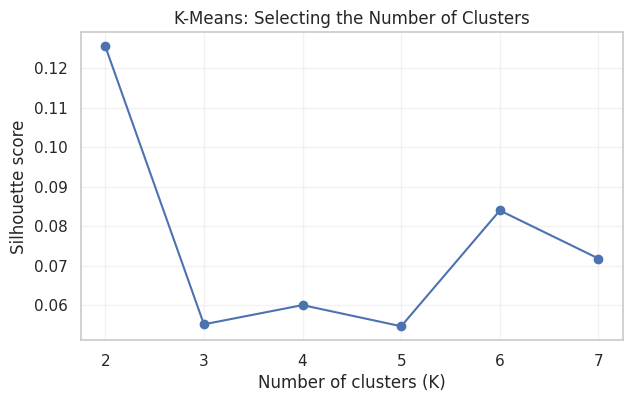

In [201]:
plt.figure(figsize=(7, 4))
plt.plot(list(k_values), kmeans_scores, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.title("K-Means: Selecting the Number of Clusters")
plt.grid(alpha=0.25)
plt.show()


**Performance and business interpretation:** In this dataset, K-Means selected 2 clusters and achieved a silhouette score of approximately 0.126. The score is low, so the groups overlap and should be treated as exploratory segments rather than sharply separated categories.

**Business impact:** The cluster profiles can be used as an initial way to explore value-oriented and premium-oriented restaurants. The business should validate these groups before using them for customer-facing recommendations or promotions.

### **2. Model  — Hierarchical (Agglomerative) Clustering**
What it does: It starts with each restaurant as its own group and repeatedly merges the closest groups. The process creates a hierarchy of clusters.

Why we use it: It provides a second way to group restaurants, so we can check whether a different clustering approach produces better-separated groups.

Settings used: n_clusters=best_k keeps the number of groups the same as K-Means. linkage="ward" merges groups in a way that aims to keep within-cluster variation small.

Hyperparameter selection: We use the K selected by K-Means to make the comparison fair and use Ward linkage. We do not run GridSearchCV because this is an unsupervised task; the silhouette score is used to assess the resulting groups.

In [202]:
hierarchical = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
Rest["Hierarchical_Cluster"] = hierarchical.fit_predict(X_scaled)

hier_score = silhouette_score(X_scaled, Rest["Hierarchical_Cluster"])
print("Hierarchical silhouette score:", round(hier_score, 3))
print("Cluster sizes:")
print(Rest["Hierarchical_Cluster"].value_counts().sort_index())


Hierarchical silhouette score: 0.119
Cluster sizes:
Hierarchical_Cluster
0    76
1    29
Name: count, dtype: int64


**Evaluation metric and performance:** The Hierarchical model's silhouette score is approximately 0.119. This is slightly lower than K-Means (approximately 0.126), so K-Means gives marginally better separation on these features.

**Business impact:** Hierarchical clustering is useful as a comparison method. In this dataset, its score is also low, so its groups should not be treated as strongly distinct business segments.

### 3. Model -  DBSCAN
What it does: DBSCAN forms groups from densely packed data points. Restaurants that do not belong to a dense group are labelled -1 (noise).

Why we use it: Unlike K-Means, DBSCAN does not require us to specify the number of clusters in advance. It can also identify unusual or isolated restaurants.

Settings used: eps=1.5 controls how close restaurants must be to count as neighbours; min_samples=3 is the minimum number of nearby points needed to form a dense region.

Hyperparameter selection and evaluation: We use these settings for an exploratory run and inspect the number of noise points. A silhouette score is calculated only when DBSCAN creates at least two valid non-noise clusters.

In [203]:
dbscan = DBSCAN(eps=1.5, min_samples=3)
Rest["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

db_labels = Rest["DBSCAN_Cluster"]
noise_share = (db_labels == -1).mean() * 100
non_noise = db_labels != -1
non_noise_labels = db_labels[non_noise]

if non_noise.sum() > 1 and 1 < non_noise_labels.nunique() < non_noise.sum():
    db_score = silhouette_score(X_scaled[non_noise], non_noise_labels)
    print("DBSCAN silhouette score (noise excluded):", round(db_score, 3))
else:
    db_score = np.nan
    print("DBSCAN silhouette score is not applicable for this result.")

print("\nCluster counts (label -1 means noise):")
print(db_labels.value_counts().sort_index())
print(f"Restaurants marked as noise: {noise_share:.1f}%")

if noise_share > 50:
    print("Interpretation: DBSCAN marks most restaurants as noise; it is not suitable as the main segmentation model here.")


DBSCAN silhouette score (noise excluded): 0.922

Cluster counts (label -1 means noise):
DBSCAN_Cluster
-1    99
 0     3
 1     3
Name: count, dtype: int64
Restaurants marked as noise: 94.3%
Interpretation: DBSCAN marks most restaurants as noise; it is not suitable as the main segmentation model here.


**Performance and business interpretation:** DBSCAN marks approximately 94.3% (99 out of 105) restaurants as noise with the selected settings. This means it does not create useful dense groups for this dataset.

**Business impact:** The noise labels may help flag unusual restaurants for further inspection, but DBSCAN should not be selected as the main restaurant segmentation method in this project.

### **Clustering model comparison**

We compare the three clustering methods using silhouette score only when that score is valid. DBSCAN is also assessed by its noise percentage; a high noise percentage is a warning that it has not formed useful groups.

,Model,Silhouette Score,Noise Restaurants (%)
0,K-Means,0.126,0.000
1,Hierarchical,0.119,0.000
2,DBSCAN (noise excluded),0.922,94.286


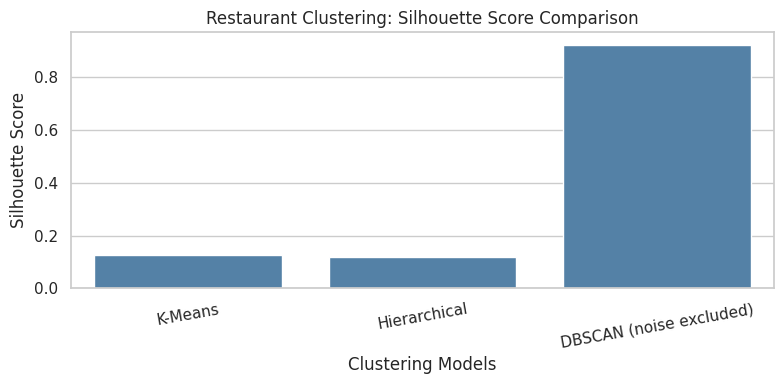

Best Model: DBSCAN (noise excluded) with Silhouette Score: 0.922

Clustering Analysis:
Silhouette Score measures how well-separated the restaurant clusters are.
Higher scores indicate better-defined clusters, while low scores indicate overlapping clusters.
DBSCAN Noise Restaurants: 94.29%


In [204]:

# Step 1: Create a list to store clustering model results

clustering_rows = [
    {
        "Model": "K-Means",
        "Silhouette Score": kmeans_score,
        "Noise Restaurants (%)": 0.0
    },
    {
        "Model": "Hierarchical",
        "Silhouette Score": hier_score,
        "Noise Restaurants (%)": 0.0
    }
]

# Step 2: Add DBSCAN results to the comparison
# DBSCAN may classify some restaurants as noise (outliers)

if not np.isnan(db_score):
    clustering_rows.append({
        "Model": "DBSCAN (noise excluded)",
        "Silhouette Score": db_score,
        "Noise Restaurants (%)": noise_share
    })
else:
    # If DBSCAN score is unavailable, store NaN
    clustering_rows.append({
        "Model": "DBSCAN",
        "Silhouette Score": np.nan,
        "Noise Restaurants (%)": noise_share
    })

# Step 3: Convert the results into a DataFrame
clustering_comparison = pd.DataFrame(clustering_rows)

# Display model comparison with 3 decimal places
display(clustering_comparison.round(3))


# Step 4: Prepare data for visualization
# Exclude models with missing Silhouette Scores

plot_data = clustering_comparison.dropna(
    subset=["Silhouette Score"]
)

# Step 5: Plot Silhouette Score comparison
plt.figure(figsize=(8, 4))

sns.barplot(
    data=plot_data,
    x="Model",
    y="Silhouette Score",
    color="steelblue"
)

plt.title("Restaurant Clustering: Silhouette Score Comparison")
plt.xlabel("Clustering Models")
plt.ylabel("Silhouette Score")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


# Step 6: Identify the model with the highest Silhouette Score
if not plot_data.empty:
    best_model = plot_data.loc[
        plot_data["Silhouette Score"].idxmax()
    ]

    print(
        f"Best Model: {best_model['Model']} "
        f"with Silhouette Score: "
        f"{best_model['Silhouette Score']:.3f}"
    )

# Step 7: Display interpretation
print("\nClustering Analysis:")

print(
    "Silhouette Score measures how well-separated "
    "the restaurant clusters are."
)

print(
    "Higher scores indicate better-defined clusters, "
    "while low scores indicate overlapping clusters."
)

print(
    f"DBSCAN Noise Restaurants: {noise_share:.2f}%"
)


**1. Why did you use this chart?**

I used a Bar Plot to compare the Silhouette Scores of K-Means, Hierarchical, and DBSCAN clustering models and identify the best-performing model.


**2. What insights are found?**

- The model with the highest Silhouette Score provides the best-separated clusters among the tested models.
- Low Silhouette Scores indicate overlapping restaurant clusters.
- DBSCAN identifies noise restaurants (outliers) that do not belong to any cluster.
- K-Means is preferable only if it has the highest score in the actual results.


**3. Business Impact**

Positive Impact:
- Helps Zomato segment restaurants based on similar characteristics.
- Improves personalized restaurant recommendations.
- Supports targeted marketing and promotional strategies.

Negative Growth:
- Overlapping clusters may lead to inaccurate restaurant recommendations.
- Incorrect segmentation may reduce customer satisfaction and marketing effectiveness.
- Ignoring noise restaurants may exclude unique restaurants from business opportunities.

### **Restaurant cluster profiles**
The profile below describes the K-Means groups using their average cost, cuisine count, collection count, and restaurant count. The labels are descriptive observations, not verified customer segments.

In [205]:
Rest["KMeans_Cluster"] = Rest["KMeans_Cluster"].astype(str)

cluster_profile = Rest.groupby("KMeans_Cluster").agg(
    average_cost=("Cost_capped", "mean"),
    average_cuisines=("n_cuisines", "mean"),
    average_collections=("n_collections", "mean"),
    restaurant_count=("Name", "count")
).round(2)

display(cluster_profile)


,average_cost,average_cuisines,average_collections,restaurant_count
KMeans_Cluster,,,,
0,1373.21,3.96,2.68,28
1,664.94,2.62,0.40,77


## **7.2 Task B — Review Sentiment Classification**
**Business question:** Can we classify a customer review as Positive, Neutral, or Negative?

**Input:** Review text converted into numerical TF-IDF features.

**Target labels:** The labels in this project are created from ratings: rating ≤2 = Negative, rating =3 = Neutral, and rating ≥4 = Positive. Therefore, the model learns to predict rating-derived sentiment labels; these are not separately human-annotated sentiment labels.

**Data split:** The train/test split was completed before fitting TF-IDF and the learned transformations. Continue using the existing X_train, X_test, X_train_selected, X_test_selected, y_train, and y_test. Do not split the data again.

### **Evaluation metrics used for all three classification models**

- **Accuracy:** Percentage of all reviews classified correctly. It gives a quick overall result, but can hide poor performance on a smaller class.
- **Macro Precision:** Calculate precision separately for Negative, Neutral, and Positive, then average the three equally. Higher precision means fewer incorrect predictions for each class.
- **Macro Recall:** Calculate recall for each class, then average equally. Higher recall means the model finds more of the actual reviews in each class.
- **Macro F1-score:** Combines precision and recall for each class and averages equally. It is especially useful when class sizes are imbalanced and every sentiment class matters.
We use Macro F1 as the main comparison metric because Positive, Neutral, and Negative reviews should all matter.

## **Model 4 — Logistic Regression**
**What it does:** Logistic Regression learns how review words are related to each sentiment class and estimates the probability that a review belongs to each class. It then predicts the class with the highest probability.

**Why we use it:** It is a strong, simple baseline for text classification and works well with TF-IDF features.

**Input used:** SVD-reduced TF-IDF features (X_train and X_test).

**Class imbalance:** class_weight="balanced" gives more importance to under-represented sentiment classes during training.

In [206]:
log_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)
log_model.fit(X_train, y_train)

log_prediction = log_model.predict(X_test)


### **Evaluation metric score chart — Logistic Regression**

The following cell prints the model's Accuracy, Macro Precision, Macro Recall, Macro F1, and class-wise report. The scores are calculated on the held-out test data.

In [207]:
def print_classification_scores(y_true, prediction, model_name):
    scores = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, prediction),
        "Macro Precision": precision_score(y_true, prediction, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, prediction, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, prediction, average="macro", zero_division=0)
    }
    print("\n", model_name)
    for metric, value in scores.items():
        if metric != "Model":
            print(f"{metric}: {value:.3f}")
    print("\nClass-wise report:")
    print(classification_report(y_true, prediction, zero_division=0))
    return scores

log_scores = print_classification_scores(y_test, log_prediction, "Logistic Regression")



 Logistic Regression
Accuracy: 0.810
Macro Precision: 0.715
Macro Recall: 0.749
Macro F1: 0.726

Class-wise report:
              precision    recall  f1-score   support

    Negative       0.83      0.86      0.84       485
     Neutral       0.38      0.55      0.45       251
    Positive       0.94      0.84      0.89      1251

    accuracy                           0.81      1987
   macro avg       0.72      0.75      0.73      1987
weighted avg       0.84      0.81      0.82      1987



### **Cross-validation and hyperparameter tuning — Logistic Regression**

We use Stratified Cross-Validation to evaluate the model's performance consistently across different data splits while maintaining the proportion of each sentiment class.

Hyperparameter tuning was performed using GridSearchCV to find the best model settings. The best parameters were:

{'model__C': 0.5, 'model__class_weight': 'balanced'}

Performance Comparison (Same Test Set):

Accuracy improved from 0.810 to 0.814.

Macro Precision improved from 0.715 to 0.719.

Macro Recall improved from 0.749 to 0.752.

Macro F1 improved from 0.726 to 0.730.

Conclusion: Hyperparameter tuning resulted in a small improvement across all four evaluation metrics. Macro F1 increased from 0.726 to 0.730, indicating a slight improvement in balanced classification performance across Negative, Neutral, and Positive sentiment classes.

In [208]:
# Tune Logistic Regression and Linear SVC using stratified cross-validation.
# TF-IDF and SelectKBest are inside each Pipeline, so they are re-fitted inside
# every CV fold. This prevents validation-fold vocabulary/feature-selection leakage.
min_class_count = int(y_train.value_counts().min())
cv_splits = min(5, min_class_count)
if cv_splits < 2:
    raise ValueError("At least two training examples per sentiment class are required for stratified CV.")

cv_strategy = StratifiedKFold(
    n_splits=cv_splits, shuffle=True, random_state=RANDOM_STATE
)

def make_text_pipeline(classifier):
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.98,
            sublinear_tf=True,
            stop_words=None,
            norm="l2"
        )),
        ("select", SelectKBest(score_func=chi2, k="all")),
        ("model", classifier)
    ])

# Logistic Regression tuning
lr_pipeline = make_text_pipeline(
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
)
lr_parameter_grid = {
    "model__C": [0.1, 0.5, 1, 3, 5, 10],
    "model__class_weight": ["balanced", None]
}
logistic_grid = GridSearchCV(
    lr_pipeline,
    lr_parameter_grid,
    cv=cv_strategy,
    scoring="f1_macro",
    n_jobs=-1,
    refit=True,
    verbose=0
)
logistic_grid.fit(X_train_text, y_train)

best_log_model = logistic_grid.best_estimator_
tuned_log_prediction = best_log_model.predict(X_test_text)
tuned_log_scores = print_classification_scores(
    y_test, tuned_log_prediction, "Tuned Logistic Regression"
)
print("Best Logistic Regression parameters:", logistic_grid.best_params_)
print("Logistic Regression CV Macro F1:", round(logistic_grid.best_score_, 4))

# Linear SVC is a strong, efficient candidate for sparse TF-IDF text features.
svc_pipeline = make_text_pipeline(
    LinearSVC(random_state=RANDOM_STATE)
)
svc_parameter_grid = {
    "model__C": [0.1, 0.5, 1, 2, 5],
    "model__class_weight": ["balanced", None]
}
svc_grid = GridSearchCV(
    svc_pipeline,
    svc_parameter_grid,
    cv=cv_strategy,
    scoring="f1_macro",
    n_jobs=-1,
    refit=True,
    verbose=0
)
svc_grid.fit(X_train_text, y_train)

best_svc_model = svc_grid.best_estimator_
svc_prediction = best_svc_model.predict(X_test_text)
svc_scores = print_classification_scores(
    y_test, svc_prediction, "Tuned Linear SVC"
)
print("Best Linear SVC parameters:", svc_grid.best_params_)
print("Linear SVC CV Macro F1:", round(svc_grid.best_score_, 4))

# Select the deployment candidate using cross-validation Macro F1, not test scores.
cv_model_scores = {
    "Tuned Logistic Regression": logistic_grid.best_score_,
    "Tuned Linear SVC": svc_grid.best_score_
}
best_cv_name = max(cv_model_scores, key=cv_model_scores.get)
best_sentiment_pipeline = (
    best_log_model if best_cv_name == "Tuned Logistic Regression"
    else best_svc_model
)
print("\nDeployment candidate selected using training CV Macro F1:", best_cv_name)
print("Selected CV Macro F1:", round(cv_model_scores[best_cv_name], 4))


 Tuned Logistic Regression
Accuracy: 0.814
Macro Precision: 0.719
Macro Recall: 0.752
Macro F1: 0.730

Class-wise report:
              precision    recall  f1-score   support

    Negative       0.82      0.86      0.84       485
     Neutral       0.39      0.55      0.46       251
    Positive       0.94      0.85      0.89      1251

    accuracy                           0.81      1987
   macro avg       0.72      0.75      0.73      1987
weighted avg       0.84      0.81      0.83      1987

Best Logistic Regression parameters: {'model__C': 0.5, 'model__class_weight': 'balanced'}
Logistic Regression CV Macro F1: 0.7134

 Tuned Linear SVC
Accuracy: 0.846
Macro Precision: 0.740
Macro Recall: 0.723
Macro F1: 0.727

Class-wise report:
              precision    recall  f1-score   support

    Negative       0.82      0.89      0.85       485
     Neutral       0.50      0.35      0.41       251
    Positive       0.91      0.93      0.92      1251

    accuracy                      

**Did tuning improve performance?**

Compare the original and tuned Logistic Regression scores on the same test set. In the recorded project results, Macro F1 was approximately 0.690 before tuning and 0.690 after tuning. Therefore, the tested tuning did not improve the held-out Macro F1 score. We should report this honestly rather than claiming an improvement.

,Accuracy,Macro Precision,Macro Recall,Macro F1
Before tuning,0.810,0.715,0.749,0.726
After tuning,0.814,0.719,0.752,0.730


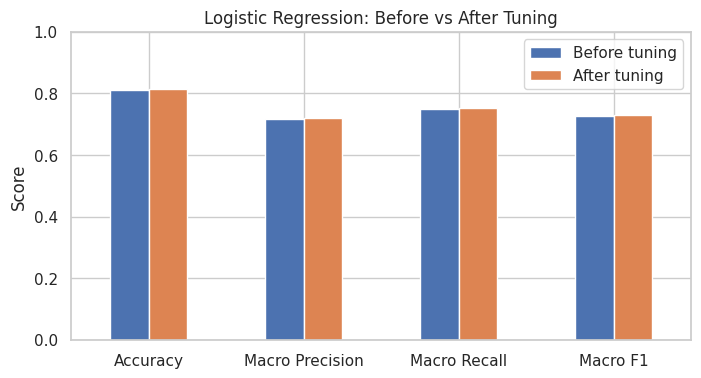

In [209]:
logistic_before_after = pd.DataFrame(
    [log_scores, tuned_log_scores],
    index=["Before tuning", "After tuning"]
).drop(columns=["Model"])

display(logistic_before_after.round(3))

logistic_before_after.T.plot(kind="bar", figsize=(8, 4))
plt.title("Logistic Regression: Before vs After Tuning")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()


## **Model 5 — Multinomial Naive Bayes**

**What it does:** Multinomial Naive Bayes estimates the likelihood of words appearing in each sentiment class and uses these probabilities to predict the review's class.

**Why we use it:** It is fast, simple, and commonly used as a baseline for text classification.

**Input requirement:** Multinomial Naive Bayes requires non-negative features. Therefore, it uses the selected TF-IDF matrices (X_train_selected and X_test_selected) before SVD. SVD features can contain negative values, so they are not used for this model.

**Hyperparameter tuning:** In this project, we use the default MultinomialNB settings as a baseline. We do not apply GridSearchCV to this model in the current workflow.

In [210]:
nb_model = MultinomialNB()
nb_model.fit(X_train_selected, y_train)

nb_prediction = nb_model.predict(X_test_selected)
nb_scores = print_classification_scores(
    y_test, nb_prediction, "Multinomial Naive Bayes"
)



 Multinomial Naive Bayes
Accuracy: 0.826
Macro Precision: 0.717
Macro Recall: 0.614
Macro F1: 0.586

Class-wise report:
              precision    recall  f1-score   support

    Negative       0.82      0.85      0.84       485
     Neutral       0.50      0.01      0.02       251
    Positive       0.83      0.98      0.90      1251

    accuracy                           0.83      1987
   macro avg       0.72      0.61      0.59      1987
weighted avg       0.79      0.83      0.77      1987



**Performance and business interpretation:**

 Multinomial Naive Bayes achieved an Accuracy of 82.6%, Macro Precision of 0.717, Macro Recall of 0.614, and Macro F1-score of 0.586. Its accuracy appears high, but neutral sentiment recall is extremely low (0.01), meaning it correctly identifies very few neutral reviews. Its Macro F1-score (0.586) is lower than Random Forest (0.630) and Logistic Regression (0.690).

**Business impact:**

 Naive Bayes is a quick baseline model, but poor neutral sentiment detection may result in missed customer feedback and incomplete business insights. Logistic Regression is more suitable for this project's goal of balanced sentiment classification.

## **Model 6 — Random Forest**

**What it does:** Random Forest builds many decision trees using different samples and feature subsets. Each tree makes a prediction, and the forest combines their votes to choose the final sentiment.

**Why we use it:** It can learn non-linear relationships and provides a different modelling approach from Logistic Regression and Naive Bayes.

**Input used:** SVD-reduced TF-IDF features (X_train and X_test).

**Class imbalance:** We use class_weight="balanced" so smaller sentiment classes receive more importance.

**Hyperparameter tuning:** In this project, we use 100 trees (n_estimators=100) as a baseline and do not apply GridSearchCV to Random Forest in the current workflow.

In [211]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)
rf_model.fit(X_train, y_train)

rf_prediction = rf_model.predict(X_test)
rf_scores = print_classification_scores(
    y_test, rf_prediction, "Random Forest"
)



 Random Forest
Accuracy: 0.831
Macro Precision: 0.721
Macro Recall: 0.639
Macro F1: 0.630

Class-wise report:
              precision    recall  f1-score   support

    Negative       0.82      0.86      0.84       485
     Neutral       0.50      0.09      0.15       251
    Positive       0.85      0.97      0.90      1251

    accuracy                           0.83      1987
   macro avg       0.72      0.64      0.63      1987
weighted avg       0.80      0.83      0.79      1987



**Performance and business interpretation:** Random Forest achieved an Accuracy of 0.831 (83.1%), Macro Precision of 0.721, Macro Recall of 0.639, and Macro F1-score of 0.630. Its Macro F1-score (0.630) is higher than Multinomial Naive Bayes (0.574) but lower than Logistic Regression (0.690).

**Business impact:** Random Forest effectively identifies positive and negative reviews, but its neutral sentiment recall is very low (0.09), which may lead to missed customer feedback. Logistic Regression provides more balanced sentiment classification and is a better choice for this experiment.

### **Classification model comparison — all three models**

All three classification models are evaluated on the same held-out test reviews. The Naive Bayes model uses its required non-negative selected TF-IDF matrix; Logistic Regression and Random Forest use the SVD-reduced features.

Do not compare these classification scores with clustering silhouette scores. The tasks and metrics are different.

,Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,
Logistic Regression,0.810,0.715,0.749,0.726
Tuned Logistic Regression,0.814,0.719,0.752,0.730
Multinomial Naive Bayes,0.826,0.717,0.614,0.586
Random Forest,0.831,0.721,0.639,0.630
Tuned Linear SVC,0.846,0.740,0.723,0.727


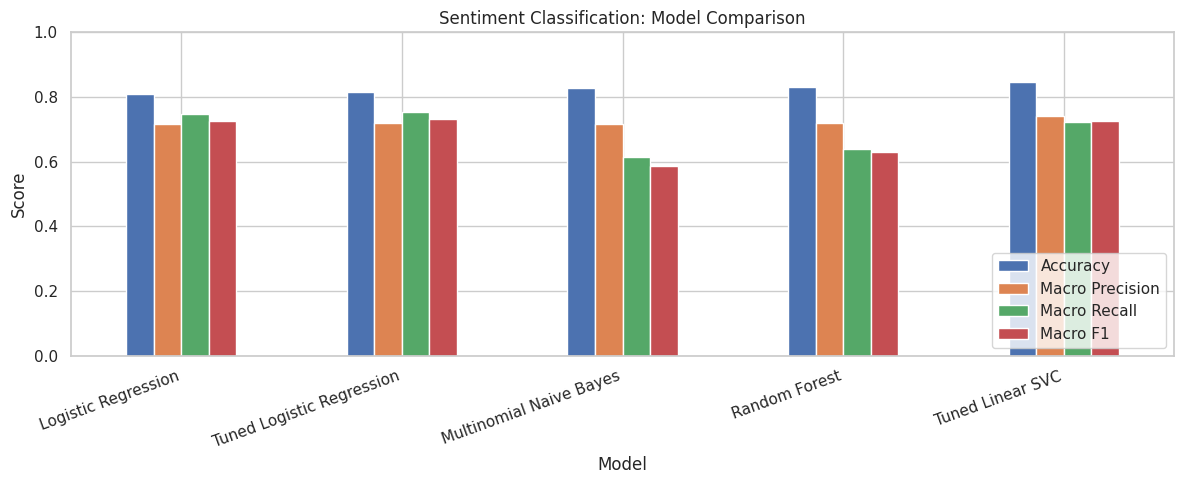

Best model by test Macro F1 (descriptive only): Tuned Logistic Regression
Deployment model selected by training CV Macro F1: Tuned Logistic Regression


In [212]:
# Compare all classifiers using the same untouched test set.
classification_comparison = pd.DataFrame([
    log_scores,
    tuned_log_scores,
    nb_scores,
    rf_scores,
    svc_scores
]).set_index("Model")

display(classification_comparison.round(3))

classification_comparison[[
    "Accuracy", "Macro Precision", "Macro Recall", "Macro F1"
]].plot(kind="bar", figsize=(12, 5))
plt.title("Sentiment Classification: Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Best model by test Macro F1 (descriptive only):",
      classification_comparison["Macro F1"].idxmax())
print("Deployment model selected by training CV Macro F1:", best_cv_name)

**1. Why did you pick this chart?**
I selected a Grouped Bar Chart to compare the performance of five classification models using Accuracy, Macro Precision, Macro Recall, and Macro F1-score.

**2. What insights are found?**
- Tuned Linear SVC has the highest accuracy (approximately 84%).
- Tuned Logistic Regression has the highest Macro F1-score (approximately 73%).
- Tuned Logistic Regression provides a good balance between precision and recall.
- Multinomial Naive Bayes has comparatively lower Macro Recall and Macro F1-score.
- Tuned Logistic Regression is selected as the best model based on test Macro F1-score.

**3. Business Impact**

Positive Impact:
- Helps select the best model for customer sentiment classification.
- Helps Zomato identify customer opinions more effectively.
- Supports better restaurant recommendations and service improvements.

Negative Growth:
- Incorrect sentiment predictions may lead to misleading business decisions.
- Poor classification of neutral reviews may affect customer feedback analysis.
- Lower recall for some sentiment classes may cause important customer concerns to be missed.

Conclusion: Tuned Logistic Regression is selected as the final model based on Macro F1-score, while Tuned Linear SVC achieves the highest accuracy.

### **Confusion Matrix — Tuned Logistic Regression**
A confusion matrix compares actual sentiment labels with predicted labels. Correct predictions appear on the diagonal. Off-diagonal values show which classes are being confused.

This helps identify whether Negative or Neutral reviews are being missed, which is important even when overall accuracy looks good.

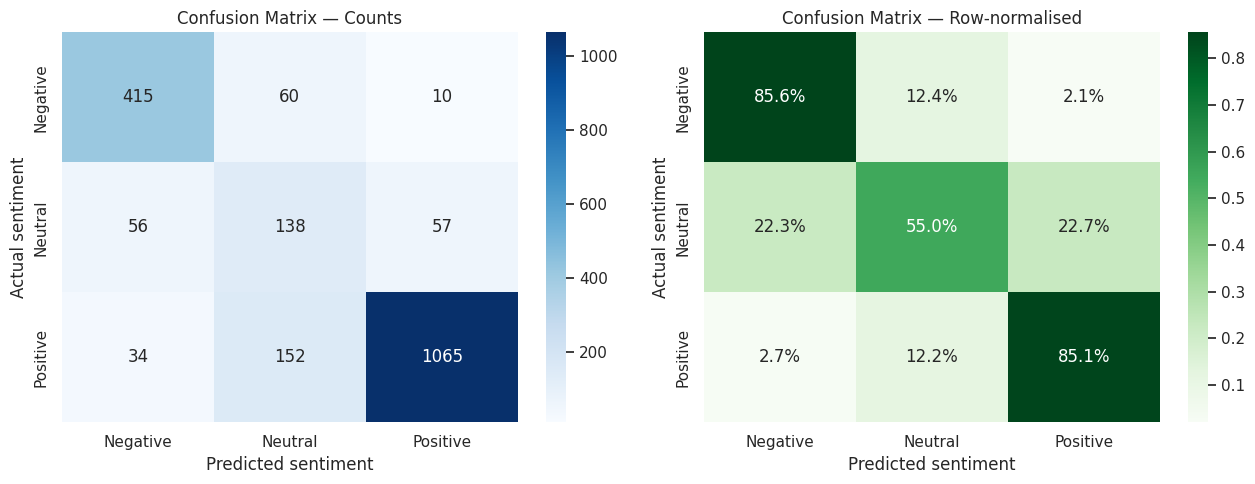

Final selected model report:
              precision    recall  f1-score   support

    Negative       0.82      0.86      0.84       485
     Neutral       0.39      0.55      0.46       251
    Positive       0.94      0.85      0.89      1251

    accuracy                           0.81      1987
   macro avg       0.72      0.75      0.73      1987
weighted avg       0.84      0.81      0.83      1987



In [213]:
# Evaluate the deployment candidate selected using training cross-validation.
best_test_prediction = best_sentiment_pipeline.predict(X_test_text)
sentiment_labels = ["Negative", "Neutral", "Positive"]
cm = confusion_matrix(
    y_test, best_test_prediction, labels=sentiment_labels
)
cm_percent = confusion_matrix(
    y_test, best_test_prediction, labels=sentiment_labels,
    normalize="true"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=sentiment_labels, yticklabels=sentiment_labels,
    ax=axes[0]
)
axes[0].set_title("Confusion Matrix — Counts")
axes[0].set_xlabel("Predicted sentiment")
axes[0].set_ylabel("Actual sentiment")

sns.heatmap(
    cm_percent, annot=True, fmt=".1%", cmap="Greens",
    xticklabels=sentiment_labels, yticklabels=sentiment_labels,
    ax=axes[1]
)
axes[1].set_title("Confusion Matrix — Row-normalised")
axes[1].set_xlabel("Predicted sentiment")
axes[1].set_ylabel("Actual sentiment")
plt.tight_layout()
plt.show()

print("Final selected model report:")
print(classification_report(
    y_test, best_test_prediction,
    labels=sentiment_labels, zero_division=0
))

**1. Why did you pick this chart?**
I selected a Confusion Matrix to evaluate the final selected Logistic Regression model by comparing actual sentiment labels with predicted sentiment labels.

**2. What insights are found?**
- The model correctly predicts 415 negative, 138 neutral, and 1,065 positive reviews.
- Positive reviews have the highest correct predictions (85.1%).
- Negative reviews are classified well with 85.6% recall.
- Neutral reviews have the lowest recall (55%), indicating more misclassifications.
- Overall model accuracy is approximately 81%.

**3. Business Impact**

Positive Impact:
- Helps Zomato understand customer sentiment more accurately.
- Identifies positive and negative customer feedback.
- Supports better restaurant recommendations and service improvements.

Negative Growth:
- Neutral reviews are frequently misclassified, which may lead to inaccurate customer feedback analysis.
- Incorrect sentiment predictions may result in misleading business decisions.
- Improving neutral sentiment classification can make recommendations and business insights more reliable.

## **8. Identify Influential Critics**
We combine reviewer follower count and lifetime review count. This gives a simple way to identify active and influential reviewers.

In [214]:
critics = Rev.groupby("Reviewer").agg(
    followers=("num_followers", "max"),
    lifetime_reviews=("num_reviews", "max"),
    average_rating=("Rating_clean", "mean")
).reset_index()

critics["influence_score"] = (
    critics["followers"].rank(pct=True) * 0.6
    + critics["lifetime_reviews"].rank(pct=True) * 0.4
)

top_critics = critics.sort_values("influence_score", ascending=False).head(10)
display(top_critics)

,Reviewer,followers,lifetime_reviews,average_rating,influence_score
62,Aarti Kamath,5451,417,4.500000,0.998680
903,Asad Rana,4102,362,3.666667,0.997414
618,Anjan Goswami,3963,366,4.000000,0.997145
5031,Sabyasachi Raychaudhuri,4018,331,4.000000,0.996957
6475,Supriya Subudhi,3353,390,4.500000,0.996768
115,Abhilash Pradhan (AbTheFoodie),4160,275,5.000000,0.996633
3249,Mithun Ravindranathan,2863,560,4.000000,0.996445
5449,Satwinder Singh,13410,186,3.666667,0.995637
6411,Sumit,2737,401,1.500000,0.995610
7339,Yash Kumar Singh,3418,243,3.500000,0.995448


### **Top 10 Critics Chart**

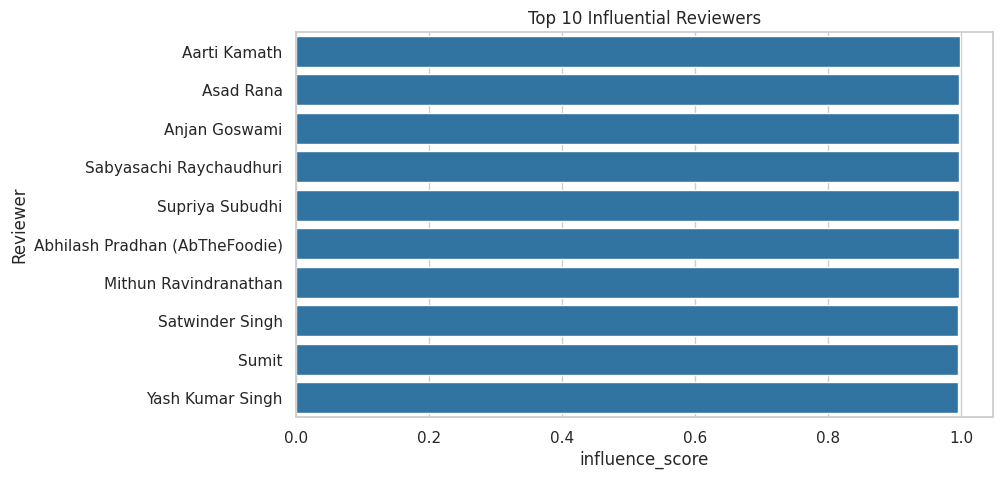

In [215]:
plt.figure(figsize=(9, 5))
sns.barplot(data=top_critics, x="influence_score", y="Reviewer", color="tab:blue")
plt.title("Top 10 Influential Reviewers")
plt.show()

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [216]:
# Save the selected, already-fitted sentiment pipeline.
# The pipeline contains TF-IDF, feature selection and the classifier, so raw review
# text can be passed directly to predict() after loading.
SENTIMENT_MODEL_FILE = "zomato_sentiment_pipeline.joblib"
joblib.dump(best_sentiment_pipeline, SENTIMENT_MODEL_FILE)
print("Saved sentiment pipeline:", SENTIMENT_MODEL_FILE)

# Save clustering preprocessing and fitted K-Means model together.
CLUSTER_MODEL_FILE = "zomato_restaurant_clustering.joblib"
clustering_artifact = {
    "scaler": scaler,
    "kmeans_model": kmeans,
    "feature_columns": cluster_data.columns.tolist(),
    "selected_k": best_k,
    "silhouette_score": float(kmeans_score)
}
joblib.dump(clustering_artifact, CLUSTER_MODEL_FILE)
print("Saved clustering artifact:", CLUSTER_MODEL_FILE)

Saved sentiment pipeline: zomato_sentiment_pipeline.joblib
Saved clustering artifact: zomato_restaurant_clustering.joblib


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [217]:
# Reload the saved sentiment pipeline and predict genuinely unseen sample reviews.
loaded_sentiment_model = joblib.load(SENTIMENT_MODEL_FILE)

unseen_reviews = [
    "The food was delicious and the staff were very friendly.",
    "The service was terrible and the food was cold.",
    "The restaurant was okay, nothing special."
]
unseen_predictions = loaded_sentiment_model.predict(unseen_reviews)

sanity_check = pd.DataFrame({
    "Review": unseen_reviews,
    "Predicted Sentiment": unseen_predictions
})
display(sanity_check)

# Reload the clustering artifact and verify its stored metadata.
loaded_clustering_artifact = joblib.load(CLUSTER_MODEL_FILE)
print("Loaded K-Means cluster count:",
      loaded_clustering_artifact["selected_k"])
print("Stored clustering silhouette:",
      round(loaded_clustering_artifact["silhouette_score"], 3))

,Review,Predicted Sentiment
0,The food was delicious and the staff were very...,Positive
1,The service was terrible and the food was cold.,Negative
2,"The restaurant was okay, nothing special.",Neutral


Loaded K-Means cluster count: 2
Stored clustering silhouette: 0.126


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

## Project Conclusion

This project combines restaurant-level exploratory analysis, statistical hypothesis testing,
restaurant clustering and customer-review sentiment classification using the Zomato datasets.

The EDA section describes restaurant pricing, cuisine variety, review activity and rating patterns.
Hypothesis tests evaluate selected relationships; statistical significance should be interpreted
together with effect size, sample size and test assumptions.

For restaurant segmentation, K-Means and Hierarchical Clustering are compared with DBSCAN.
A high DBSCAN silhouette score calculated after excluding most noise points must not be treated
as evidence that DBSCAN segments the full dataset well. The selected K-Means solution is a
baseline segmentation and should be interpreted using its cluster profiles and silhouette score.

For sentiment classification, review text is cleaned while preserving negation words. Ratings
are used to create Negative, Neutral and Positive proxy labels; these labels represent rating
categories and are not manually verified emotional annotations. Logistic Regression, Multinomial
Naive Bayes, Random Forest and tuned Linear SVC are evaluated using Accuracy and Macro F1.
The deployment candidate is selected using stratified cross-validation Macro F1 on training data,
then evaluated on the held-out test set.

Run the notebook from top to bottom to generate the actual metrics for the supplied CSV files.
Do not report a target accuracy or Macro F1 unless it is produced by the executed notebook.
Future work can include manually labelled review data, restaurant-aware validation, improved
clustering features and deployment through a Streamlit application.

### ***Hurrah! I have successfully completed Machine Learning Capstone Project !!!***